# 🎓 Student Performance Analytics & Prediction

---

**Internship Programme:** IBM SkillsBuild – Data Analytics with AI Internship 2026  
**Project Type:** Academic Capstone Project  
**Dataset:** Student Performance and Learning Behavior Dataset (Kaggle)  
**Dataset Source:** https://www.kaggle.com/datasets/adilshamim8/student-performance-and-learning-style  

---

## 1. Project Overview

This project applies data analytics and machine learning techniques to understand the factors that influence student academic performance and to build a predictive model capable of forecasting a student's final grade based on their learning behaviour and personal attributes.

The analysis follows a standard data science pipeline:

1. Data collection and loading  
2. Exploratory data analysis (EDA)  
3. Statistical analysis  
4. Feature engineering  
5. Machine learning model training and evaluation  
6. Interpretation of findings and actionable recommendations  

The entire project is contained in this single reproducible Jupyter Notebook.

## 2. Problem Statement

Educational institutions face a persistent challenge: identifying at-risk students early enough to intervene effectively. Traditional approaches rely on end-of-semester grades, by which point it is often too late to offer meaningful support.

**Core question:**  
> *Can we use a student's study habits, attendance, motivation, technology usage, and demographic attributes to predict their final academic grade before the end of the semester?*

Answering this question enables educators and administrators to:
- Target academic support resources at students with the highest risk of poor outcomes.
- Understand which behavioural factors are most strongly correlated with performance.
- Design evidence-based interventions to improve overall institutional outcomes.

## 3. Objectives

The specific objectives of this project are:

1. **Explore** the dataset to understand its structure, distributions, and relationships between variables.
2. **Identify** the most significant predictors of student academic performance.
3. **Analyse** statistical relationships between behavioural and demographic features and the final grade.
4. **Engineer** meaningful features to improve model performance.
5. **Train and evaluate** multiple regression models to predict `ExamScore`, the primary continuous performance indicator.
6. **Select** the best-performing model and interpret its predictions.
7. **Derive** actionable recommendations for educators and policymakers based on findings.

## 4. Dataset Description

**File:** `student_performance.csv`  
**Records:** 14,003 students  
**Features:** 16 columns (15 input features + 1 target variable)  
**Missing values:** None  
**All columns are integer-encoded.**

| # | Column | Type | Description | Value Mapping |
|---|--------|------|-------------|---------------|
| 0 | `StudyHours` | Numeric | Weekly hours spent studying | 5 – 44 |
| 1 | `Attendance` | Numeric | Class attendance percentage | 60 – 100 |
| 2 | `Resources` | Ordinal | Access to learning resources | 0=Low, 1=Medium, 2=High |
| 3 | `Extracurricular` | Binary | Participates in extracurricular activities | 0=No, 1=Yes |
| 4 | `Motivation` | Ordinal | Self-reported motivation level | 0=Low, 1=Medium, 2=High |
| 5 | `Internet` | Binary | Has reliable internet access | 0=No, 1=Yes |
| 6 | `Gender` | Binary | Student gender | 0=Female, 1=Male |
| 7 | `Age` | Numeric | Student age (years) | 18 – 29 |
| 8 | `LearningStyle` | Nominal | Preferred learning style | 0=Visual, 1=Auditory, 2=Reading/Writing, 3=Kinesthetic |
| 9 | `OnlineCourses` | Numeric | Number of online courses completed | Varies |
| 10 | `Discussions` | Binary | Participates in class discussions | 0=No, 1=Yes |
| 11 | `AssignmentCompletion` | Numeric | Percentage of assignments completed | 0 – 100 |
| 12 | `ExamScore` | Numeric | Average exam score | 0 – 100 |
| 13 | `EduTech` | Binary | Uses educational technology tools | 0=No, 1=Yes |
| 14 | `StressLevel` | Ordinal | Self-reported stress level | 0=Low, 1=Medium, 2=High |
| 15 | `FinalGrade` | **Target** | Final academic grade (ordinal) | 0=A, 1=B, 2=C, 3=F |

> **Target variable:** `FinalGrade` is derived from `ExamScore` via fixed grade bands (0=A: 85–100, 1=B: 70–84, 2=C: 55–69, 3=F: 40–54). The ML section predicts `ExamScore` directly (regression) to avoid the information loss of binning. `FinalGrade` is excluded from model features to prevent data leakage.

## 5. Import Libraries

In [1]:
# ── Core data handling ────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# ── Statistical analysis ──────────────────────────────────────────────────────
from scipy import stats
from scipy import stats as scipy_stats

# ── Machine learning — model selection & preprocessing ───────────────────────
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler

# ── Machine learning — regression models ─────────────────────────────────────
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# ── Machine learning — evaluation metrics ────────────────────────────────────
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ── Reproducibility & display ─────────────────────────────────────────────────
import warnings
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 100

print("All libraries imported successfully.")
print(f"  numpy  {np.__version__}  |  pandas {pd.__version__}  |  seaborn {sns.__version__}")
import sklearn; print(f"  scikit-learn {sklearn.__version__}")


All libraries imported successfully.
  numpy  2.5.3  |  pandas 3.0.6  |  seaborn 0.13.2
  scikit-learn 1.9.1


## 6. Load Dataset

In [2]:
# Load the dataset
df = pd.read_csv('student_performance.csv')

print(f'Dataset loaded successfully.')
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
print()
print('First 5 rows:')
df.head()

Dataset loaded successfully.
Shape: 14,003 rows × 16 columns

First 5 rows:


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


## 7. Data Understanding

This section systematically examines the raw dataset before any modification. The goal is to understand its shape, structure, data types, value distributions, missing data, and duplicate records so that every subsequent cleaning decision is grounded in evidence rather than assumption.

In [3]:
# ── 7.1  Shape and first / last rows ─────────────────────────────────────────
print(f"Dataset shape : {df.shape[0]:,} rows  x  {df.shape[1]} columns")
print()
print("=== FIRST 5 ROWS ===")
display(df.head())
print("=== LAST 5 ROWS ===")
display(df.tail())

Dataset shape : 14,003 rows  x  16 columns

=== FIRST 5 ROWS ===


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


=== LAST 5 ROWS ===


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
13998,30,62,0,1,1,1,0,22,2,2,1,100,71,1,2,1
13999,30,62,0,1,1,1,0,23,3,12,1,72,55,1,1,2
14000,22,90,2,0,1,1,0,23,3,0,1,80,56,0,0,2
14001,22,90,2,0,1,1,0,29,2,16,0,50,62,1,2,2
14002,10,86,2,1,2,1,0,18,2,8,1,66,77,1,2,1


In [4]:
# ── 7.2  Column names and data types ─────────────────────────────────────────
dtype_df = pd.DataFrame({
    "Column":        df.columns.tolist(),
    "DType":         df.dtypes.astype(str).tolist(),
    "Non-Null":      df.notnull().sum().tolist(),
    "Unique Values": df.nunique().tolist(),
    "Min":           df.min().tolist(),
    "Max":           df.max().tolist(),
})
print("=== COLUMN OVERVIEW ===")
display(dtype_df.to_string(index=False))

=== COLUMN OVERVIEW ===


'              Column DType  Non-Null  Unique Values  Min  Max\n          StudyHours int64     14003             37    5   44\n          Attendance int64     14003             41   60  100\n           Resources int64     14003              3    0    2\n     Extracurricular int64     14003              2    0    1\n          Motivation int64     14003              3    0    2\n            Internet int64     14003              2    0    1\n              Gender int64     14003              2    0    1\n                 Age int64     14003             12   18   29\n       LearningStyle int64     14003              4    0    3\n       OnlineCourses int64     14003             21    0   20\n         Discussions int64     14003              2    0    1\nAssignmentCompletion int64     14003             51   50  100\n           ExamScore int64     14003             61   40  100\n             EduTech int64     14003              2    0    1\n         StressLevel int64     14003              3   

In [5]:
# ── 7.3  Missing value audit ─────────────────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(4)
missing_df = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
total_missing = int(missing.sum())

if total_missing == 0:
    print(f"No missing values found across all {df.shape[1]} columns.  All cells are populated.")
else:
    print("Columns with missing values:")
    print(missing_df[missing_df["Missing Count"] > 0].to_string())
print(f"\nTotal missing cells : {total_missing}")

No missing values found across all 16 columns.  All cells are populated.

Total missing cells : 0


In [6]:
# ── 7.4  Duplicate row audit ─────────────────────────────────────────────────
n_total      = len(df)
n_duplicates = df.duplicated().sum()
n_unique     = n_total - n_duplicates
dup_pct      = n_duplicates / n_total * 100

print(f"Total rows      : {n_total:,}")
print(f"Duplicate rows  : {n_duplicates:,}  ({dup_pct:.2f}%)")
print(f"Unique rows     : {n_unique:,}")

# Show a sample of duplicated rows for inspection
if n_duplicates > 0:
    dup_mask = df.duplicated(keep=False)
    sample_dups = df[dup_mask].sort_values(list(df.columns)).head(8)
    print("\nSample of duplicated records (first 8 rows from duplicate groups):")
    display(sample_dups)

Total rows      : 14,003
Duplicate rows  : 1,534  (10.95%)
Unique rows     : 12,469

Sample of duplicated records (first 8 rows from duplicate groups):


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
3249,7,82,2,1,1,1,1,18,1,20,1,60,75,1,2,1
3251,7,82,2,1,1,1,1,18,1,20,1,60,75,1,2,1
3248,7,82,2,1,1,1,1,27,2,15,1,54,44,0,2,3
3250,7,82,2,1,1,1,1,27,2,15,1,54,44,0,2,3
9938,9,87,1,0,1,1,0,23,1,17,0,56,83,1,2,1
9943,9,87,1,0,1,1,0,23,1,17,0,56,83,1,2,1
9934,9,87,1,0,1,1,0,24,1,11,0,88,95,0,2,0
9939,9,87,1,0,1,1,0,24,1,11,0,88,95,0,2,0


In [7]:
# ── 7.5  Descriptive statistics ──────────────────────────────────────────────
print("=== DESCRIPTIVE STATISTICS ===")
display(df.describe().T.round(3))

=== DESCRIPTIVE STATISTICS ===


,count,mean,std,min,25%,50%,75%,max
StudyHours,14003.0000,19.9870,5.8910,5.0000,16.0000,20.0000,24.0000,44.0000
Attendance,14003.0000,80.1940,11.4720,60.0000,70.0000,80.0000,90.0000,100.0000
Resources,14003.0000,1.1040,0.6970,0.0000,1.0000,1.0000,2.0000,2.0000
Extracurricular,14003.0000,0.5940,0.4910,0.0000,0.0000,1.0000,1.0000,1.0000
Motivation,14003.0000,0.9060,0.6960,0.0000,0.0000,1.0000,1.0000,2.0000
Internet,14003.0000,0.9260,0.2630,0.0000,1.0000,1.0000,1.0000,1.0000
Gender,14003.0000,0.5520,0.4970,0.0000,0.0000,1.0000,1.0000,1.0000
Age,14003.0000,23.5320,3.5140,18.0000,20.0000,24.0000,27.0000,29.0000
LearningStyle,14003.0000,1.5150,1.1130,0.0000,1.0000,2.0000,3.0000,3.0000
OnlineCourses,14003.0000,9.8920,6.1130,0.0000,5.0000,10.0000,15.0000,20.0000


In [8]:
# ── 7.6  Value catalogue for encoded categorical columns ──────────────────────
# Define column groups (used throughout the notebook)
CATEGORICAL_COLS = ["Resources", "Extracurricular", "Motivation", "Internet",
                    "Gender", "LearningStyle", "Discussions", "EduTech", "StressLevel"]
NUMERIC_COLS     = ["StudyHours", "Attendance", "Age", "OnlineCourses",
                    "AssignmentCompletion", "ExamScore"]
TARGET_COL       = "FinalGrade"

# Human-readable decoding maps (verified against ExamScore cross-tabulation)
GRADE_MAP    = {0: "A", 1: "B", 2: "C", 3: "F"}
GENDER_MAP   = {0: "Female", 1: "Male"}
RES_MAP      = {0: "Low", 1: "Medium", 2: "High"}
MOT_MAP      = {0: "Low", 1: "Medium", 2: "High"}
STRESS_MAP   = {0: "Low", 1: "Medium", 2: "High"}
LEARN_MAP    = {0: "Visual", 1: "Auditory", 2: "Reading/Writing", 3: "Kinesthetic"}

print("=== UNIQUE VALUES PER CATEGORICAL COLUMN ===")
for col in CATEGORICAL_COLS + [TARGET_COL]:
    vc = df[col].value_counts().sort_index()
    vals_str = ",  ".join([f"{v}={c:,}" for v, c in vc.items()])
    print(f"  {col:<25s} : {vals_str}")

=== UNIQUE VALUES PER CATEGORICAL COLUMN ===
  Resources                 : 0=2,750,  1=7,041,  2=4,212
  Extracurricular           : 0=5,683,  1=8,320
  Motivation                : 0=4,112,  1=7,098,  2=2,793
  Internet                  : 0=1,043,  1=12,960
  Gender                    : 0=6,274,  1=7,729
  LearningStyle             : 0=3,376,  1=3,580,  2=3,500,  3=3,547
  Discussions               : 0=5,519,  1=8,484
  EduTech                   : 0=4,074,  1=9,929
  StressLevel               : 0=2,836,  1=4,069,  2=7,098
  FinalGrade                : 0=3,832,  1=3,310,  2=3,618,  3=3,243


### Key Observations from Data Understanding

| Observation | Detail |
|---|---|
| **Shape** | 14,003 rows × 16 columns; all `int64` — entirely integer-encoded |
| **Missing values** | None — every cell is populated |
| **Duplicate rows** | **1,534 rows (10.95%)** are exact duplicates — requires a cleaning decision |
| **FinalGrade encoding** | Cross-tabulating `FinalGrade` against `ExamScore` shows `FinalGrade=0` has mean ExamScore 92.6 and `FinalGrade=3` has mean 46.7. The correct mapping is **0=A, 1=B, 2=C, 3=F** |
| **Numeric floors** | `AssignmentCompletion` min=50, `Attendance` min=60, `ExamScore` min=40 — by-design lower bounds, not data errors |
| **StudyHours mild outliers** | 45 values exceed the IQR upper fence of 36 hrs/week (range 37–44). These are plausible and are retained |
| **StressLevel skew** | 7,098 students (50.7%) report high stress (level 2), the most common value |
| **ExamScore–FinalGrade link** | The grade bands are perfectly non-overlapping: Grade A = ExamScore 85–100, B = 70–84, C = 55–69, F = 40–54 |

## 8. Data Cleaning and Preprocessing

### Cleaning decisions

Based on the Data Understanding findings, the following decisions are made:

1. **Duplicate rows** — 1,534 exact duplicate rows will be removed. Retaining them would artificially inflate the dataset with no new information and could bias model training.
2. **Data types** — All columns are `int64`. No type conversions are required. Ordinal and binary columns are correctly stored as integers and do not need encoding.
3. **Missing values** — None to handle.
4. **Value range validation** — All numeric columns will be verified against their expected domain bounds. Rows with impossible values (e.g., Attendance > 100) will be flagged.
5. **StudyHours mild outliers** — 45 rows have StudyHours between 37–44. These are plausible real-world values (a student studying ≈6 hrs/day) and are retained.
6. **Decoded label copy** — A separate `df_vis` dataframe with human-readable labels will be created for visualisation. All model training uses the original integer-encoded `df_clean`.

In [9]:
# ── 8.1  Remove duplicate rows ────────────────────────────────────────────────
before = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
after = len(df_clean)
removed = before - after

print(f"Rows before deduplication : {before:,}")
print(f"Rows removed              : {removed:,}  ({removed/before*100:.2f}%)")
print(f"Rows after deduplication  : {after:,}")
print()
print("Grade distribution preserved after deduplication:")
before_dist = df[TARGET_COL].value_counts(normalize=True).sort_index().round(4)
after_dist  = df_clean[TARGET_COL].value_counts(normalize=True).sort_index().round(4)
dist_check = pd.DataFrame({"Before (%)": before_dist*100, "After (%)": after_dist*100})
dist_check.index = [f"Grade {GRADE_MAP[i]}" for i in dist_check.index]
print(dist_check.round(2).to_string())

Rows before deduplication : 14,003
Rows removed              : 1,534  (10.95%)
Rows after deduplication  : 12,469

Grade distribution preserved after deduplication:
         Before (%)  After (%)
Grade A     27.3700    27.2800
Grade B     23.6400    23.6000
Grade C     25.8400    25.8300
Grade F     23.1600    23.2900


In [10]:
# ── 8.2  Value range validation ───────────────────────────────────────────────
range_specs = {
    "StudyHours":           (1,   50),
    "Attendance":           (0,  100),
    "AssignmentCompletion": (0,  100),
    "ExamScore":            (0,  100),
    "Age":                  (16,  60),
    "OnlineCourses":        (0,   50),
    "Resources":            (0,    2),
    "Extracurricular":      (0,    1),
    "Motivation":           (0,    2),
    "Internet":             (0,    1),
    "Gender":               (0,    1),
    "LearningStyle":        (0,    3),
    "Discussions":          (0,    1),
    "EduTech":              (0,    1),
    "StressLevel":          (0,    2),
    "FinalGrade":           (0,    3),
}

print(f"{'Column':<25} {'Min':>6} {'Max':>6} {'Expected':>12} {'Violations':>12} {'Status':>8}")
print("-" * 75)
total_violations = 0
for col, (lo, hi) in range_specs.items():
    col_min = int(df_clean[col].min())
    col_max = int(df_clean[col].max())
    violations = int(((df_clean[col] < lo) | (df_clean[col] > hi)).sum())
    total_violations += violations
    status = "OK" if violations == 0 else "REVIEW"
    print(f"{col:<25} {col_min:>6} {col_max:>6} {f'[{lo},{hi}]':>12} {violations:>12,} {status:>8}")

print()
print(f"Total range violations : {total_violations}")
if total_violations == 0:
    print("All values are within expected domain bounds.")

Column                       Min    Max     Expected   Violations   Status
---------------------------------------------------------------------------
StudyHours                     5     44       [1,50]            0       OK
Attendance                    60    100      [0,100]            0       OK
AssignmentCompletion          50    100      [0,100]            0       OK
ExamScore                     40    100      [0,100]            0       OK
Age                           18     29      [16,60]            0       OK
OnlineCourses                  0     20       [0,50]            0       OK
Resources                      0      2        [0,2]            0       OK
Extracurricular                0      1        [0,1]            0       OK
Motivation                     0      2        [0,2]            0       OK
Internet                       0      1        [0,1]            0       OK
Gender                         0      1        [0,1]            0       OK
LearningStyle           

In [11]:
# ── 8.3  Create decoded visualisation copy ────────────────────────────────────
df_vis = df_clean.copy()

df_vis["Grade_Label"]        = df_vis[TARGET_COL].map(GRADE_MAP)
df_vis["Gender_Label"]       = df_vis["Gender"].map(GENDER_MAP)
df_vis["Resources_Label"]    = df_vis["Resources"].map(RES_MAP)
df_vis["Motivation_Label"]   = df_vis["Motivation"].map(MOT_MAP)
df_vis["StressLevel_Label"]  = df_vis["StressLevel"].map(STRESS_MAP)
df_vis["LearningStyle_Label"]= df_vis["LearningStyle"].map(LEARN_MAP)

# Ordered category dtype so plots sort correctly
grade_order = ["A", "B", "C", "F"]
df_vis["Grade_Label"] = pd.Categorical(df_vis["Grade_Label"], categories=grade_order, ordered=True)

print("Cleaned dataset ready.")
print(f"  df_clean : {df_clean.shape[0]:,} rows  x  {df_clean.shape[1]} columns  (for modelling)")
print(f"  df_vis   : {df_vis.shape[0]:,} rows  x  {df_vis.shape[1]} columns  (for visualisation)")
print()
print("Final grade distribution in cleaned dataset:")
gd = df_clean[TARGET_COL].value_counts().sort_index()
for k, v in gd.items():
    pct = v / len(df_clean) * 100
    bar = "█" * int(pct / 1.5)
    print(f"  Grade {GRADE_MAP[k]} ({k}) : {v:>5,}  ({pct:5.1f}%)  {bar}")

Cleaned dataset ready.
  df_clean : 12,469 rows  x  16 columns  (for modelling)
  df_vis   : 12,469 rows  x  22 columns  (for visualisation)

Final grade distribution in cleaned dataset:
  Grade A (0) : 3,401  ( 27.3%)  ██████████████████
  Grade B (1) : 2,943  ( 23.6%)  ███████████████
  Grade C (2) : 3,221  ( 25.8%)  █████████████████
  Grade F (3) : 2,904  ( 23.3%)  ███████████████


### Cleaning Summary

| Step | Action | Rows Affected |
|---|---|---|
| Duplicate removal | 1,534 exact duplicate rows dropped | −1,534 |
| Missing values | None — no action required | 0 |
| Type corrections | None — all columns correctly typed as `int64` | 0 |
| Range violations | None — all values within expected domain bounds | 0 |
| Outlier treatment | 45 high-`StudyHours` values (37–44) retained as plausible | 0 |

**Working dataset after cleaning: 12,469 rows × 16 columns.**

## 9. Exploratory Data Analysis

The EDA is structured in four parts:

- **Part A — Target Variable Analysis:** Understand the class distribution of `FinalGrade`.
- **Part B — Univariate Analysis:** Distribution of each individual feature.
- **Part C — Bivariate Analysis:** How each feature relates to `FinalGrade` and to exam performance.
- **Part D — Multivariate Analysis:** Correlation structure and interaction patterns.

All findings are computed from the cleaned dataset (`df_clean`, 12,469 rows).

### Part A — Target Variable Analysis

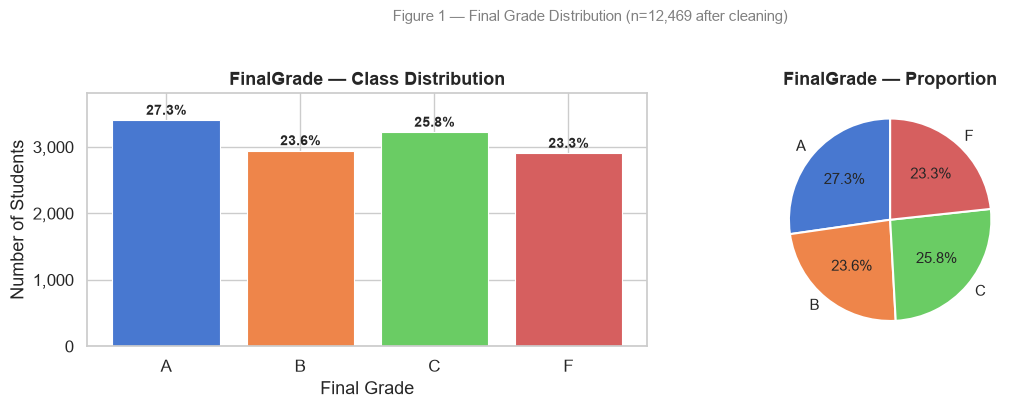

Grade distribution:
  A (0) : 3,401  (27.3%)
  B (1) : 2,943  (23.6%)
  C (2) : 3,221  (25.8%)
  F (3) : 2,904  (23.3%)


In [12]:
# ── Fig 1 : FinalGrade distribution ──────────────────────────────────────────
grade_counts = df_clean[TARGET_COL].value_counts().sort_index()
grade_labels = [GRADE_MAP[k] for k in grade_counts.index]
grade_pcts   = grade_counts / len(df_clean) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart
palette = sns.color_palette("muted", 4)
bars = axes[0].bar(grade_labels, grade_counts.values, color=palette, edgecolor="white", linewidth=0.8)
for bar, pct in zip(bars, grade_pcts.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 40,
                 f"{pct:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[0].set_title("FinalGrade — Class Distribution", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Final Grade")
axes[0].set_ylabel("Number of Students")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))
axes[0].set_ylim(0, grade_counts.max() * 1.12)

# Pie chart
wedge_props = {"linewidth": 1.5, "edgecolor": "white"}
axes[1].pie(grade_counts.values, labels=grade_labels, autopct="%1.1f%%",
            colors=palette, wedgeprops=wedge_props,
            startangle=90, textprops={"fontsize": 11})
axes[1].set_title("FinalGrade — Proportion", fontsize=13, fontweight="bold")

plt.suptitle("Figure 1 — Final Grade Distribution (n=12,469 after cleaning)",
             fontsize=11, color="grey", y=1.02)
plt.tight_layout()
plt.show()

print("Grade distribution:")
for k, v in grade_counts.items():
    print(f"  {GRADE_MAP[k]} ({k}) : {v:>5,}  ({v/len(df_clean)*100:.1f}%)")

### Part B — Univariate Analysis

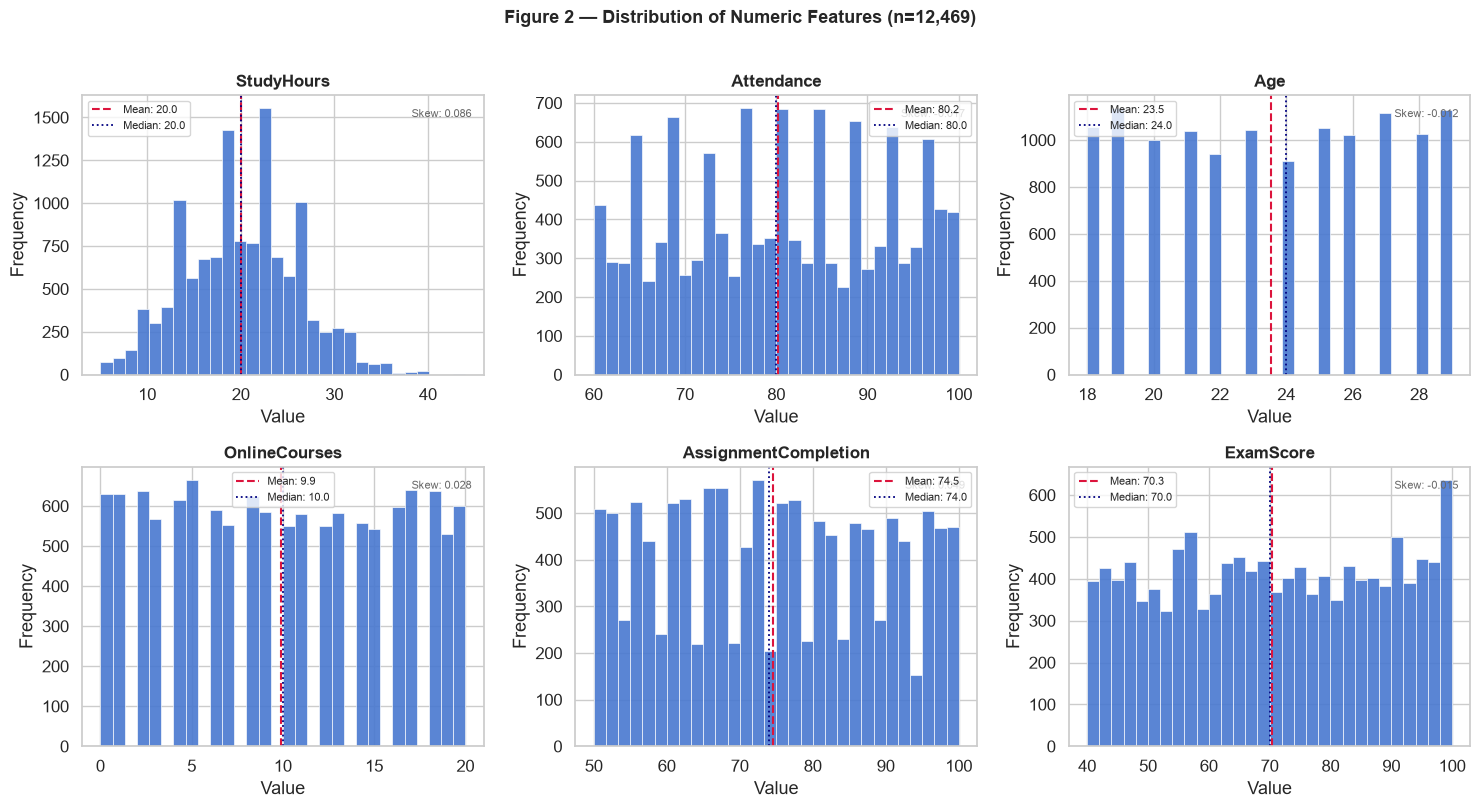

In [13]:
# ── Fig 2 : Histograms of numeric features ────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(NUMERIC_COLS):
    data = df_clean[col]
    q25, q50, q75 = data.quantile([0.25, 0.50, 0.75])
    mean_v = data.mean()

    axes[i].hist(data, bins=30, color=sns.color_palette("muted")[0],
                 edgecolor="white", linewidth=0.5, alpha=0.9)
    axes[i].axvline(mean_v, color="crimson", linestyle="--", linewidth=1.5,
                    label=f"Mean: {mean_v:.1f}")
    axes[i].axvline(q50,    color="navy",   linestyle=":",  linewidth=1.3,
                    label=f"Median: {q50:.1f}")
    axes[i].set_title(col, fontsize=12, fontweight="bold")
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")
    axes[i].legend(fontsize=8)
    # Annotate skewness
    skew = data.skew()
    axes[i].text(0.97, 0.95, f"Skew: {skew:.3f}",
                 transform=axes[i].transAxes, ha="right", va="top", fontsize=8, color="dimgray")

plt.suptitle("Figure 2 — Distribution of Numeric Features (n=12,469)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

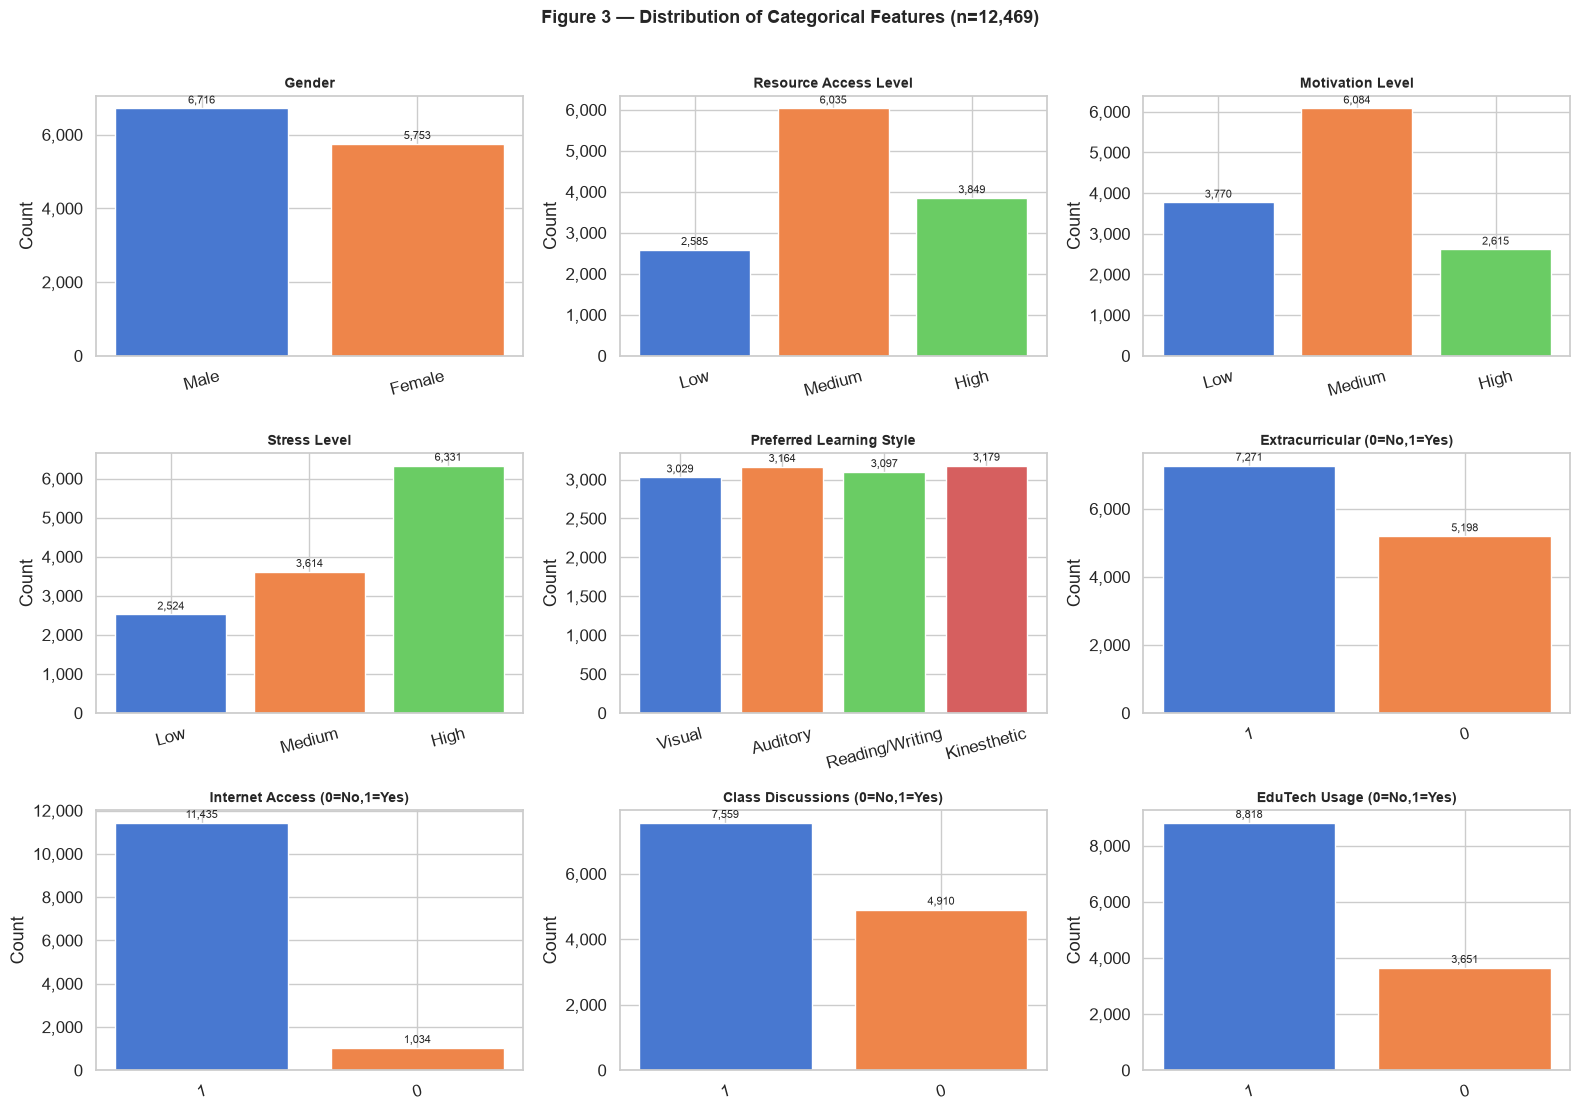

In [14]:
# ── Fig 3 : Count plots of categorical features ───────────────────────────────
cat_plot_specs = [
    ("Gender_Label",        "Gender",                   None),
    ("Resources_Label",     "Resource Access Level",    ["Low", "Medium", "High"]),
    ("Motivation_Label",    "Motivation Level",         ["Low", "Medium", "High"]),
    ("StressLevel_Label",   "Stress Level",             ["Low", "Medium", "High"]),
    ("LearningStyle_Label", "Preferred Learning Style", ["Visual", "Auditory", "Reading/Writing", "Kinesthetic"]),
    ("Extracurricular",     "Extracurricular (0=No,1=Yes)", None),
    ("Internet",            "Internet Access (0=No,1=Yes)", None),
    ("Discussions",         "Class Discussions (0=No,1=Yes)", None),
    ("EduTech",             "EduTech Usage (0=No,1=Yes)", None),
]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.flatten()

for i, (col, title, order) in enumerate(cat_plot_specs):
    counts = df_vis[col].value_counts()
    if order:
        counts = counts.reindex([o for o in order if o in counts.index])
    x_labels = counts.index.astype(str)
    bars = axes[i].bar(x_labels, counts.values,
                       color=sns.color_palette("muted", len(counts)), edgecolor="white")
    for bar in bars:
        axes[i].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + counts.max() * 0.01,
                     f"{bar.get_height():,}", ha="center", va="bottom", fontsize=8)
    axes[i].set_title(title, fontsize=10, fontweight="bold")
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", labelrotation=15)
    axes[i].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{int(x):,}"))

plt.suptitle("Figure 3 — Distribution of Categorical Features (n=12,469)",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

### Part C — Bivariate Analysis

#### C.1 — ExamScore as the Primary Performance Driver

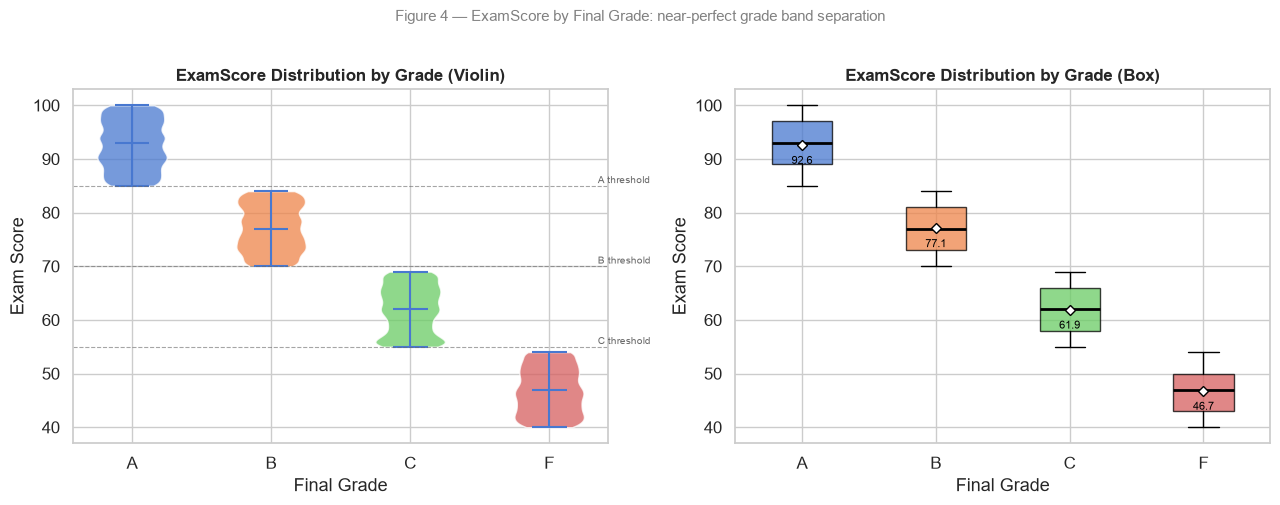

Mean ExamScore per grade:
  Grade A: 92.57
  Grade B: 77.07
  Grade C: 61.88
  Grade F: 46.75


In [15]:
# ── Fig 4 : ExamScore distribution by FinalGrade ─────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
grade_order_cat = ["A", "B", "C", "F"]
palette = sns.color_palette("muted", 4)

# Violin plot
parts = axes[0].violinplot(
    [df_vis[df_vis["Grade_Label"] == g]["ExamScore"].values for g in grade_order_cat],
    positions=[1, 2, 3, 4], showmedians=True, showmeans=False
)
for pc, col in zip(parts["bodies"], palette):
    pc.set_facecolor(col); pc.set_alpha(0.75)
axes[0].set_xticks([1, 2, 3, 4])
axes[0].set_xticklabels(grade_order_cat)
axes[0].set_title("ExamScore Distribution by Grade (Violin)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Final Grade")
axes[0].set_ylabel("Exam Score")

# Add grade band reference lines
for y, label in [(85, "A threshold"), (70, "B threshold"), (55, "C threshold")]:
    axes[0].axhline(y, color="dimgray", linestyle="--", linewidth=0.8, alpha=0.6)
    axes[0].text(4.35, y + 0.5, label, fontsize=7, color="dimgray")

# Box plot
box_data = [df_vis[df_vis["Grade_Label"] == g]["ExamScore"].values for g in grade_order_cat]
bp = axes[1].boxplot(box_data, tick_labels=grade_order_cat, patch_artist=True,
                     medianprops=dict(color="black", linewidth=2))
for patch, col in zip(bp["boxes"], palette):
    patch.set_facecolor(col); patch.set_alpha(0.75)

# Annotate means
for j, (g, col) in enumerate(zip(grade_order_cat, palette)):
    mean_v = df_vis[df_vis["Grade_Label"] == g]["ExamScore"].mean()
    axes[1].plot(j + 1, mean_v, marker="D", color="white",
                 markeredgecolor="black", markersize=5, zorder=5)
    axes[1].text(j + 1, mean_v - 3.5, f"{mean_v:.1f}", ha="center", fontsize=8, color="black")

axes[1].set_title("ExamScore Distribution by Grade (Box)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Final Grade")
axes[1].set_ylabel("Exam Score")

plt.suptitle("Figure 4 — ExamScore by Final Grade: near-perfect grade band separation",
             fontsize=11, color="grey", y=1.01)
plt.tight_layout()
plt.show()

print("Mean ExamScore per grade:")
for g in grade_order_cat:
    m = df_vis[df_vis["Grade_Label"] == g]["ExamScore"].mean()
    print(f"  Grade {g}: {m:.2f}")

#### C.2 — Study Hours, Attendance, and Assignment Completion vs Performance

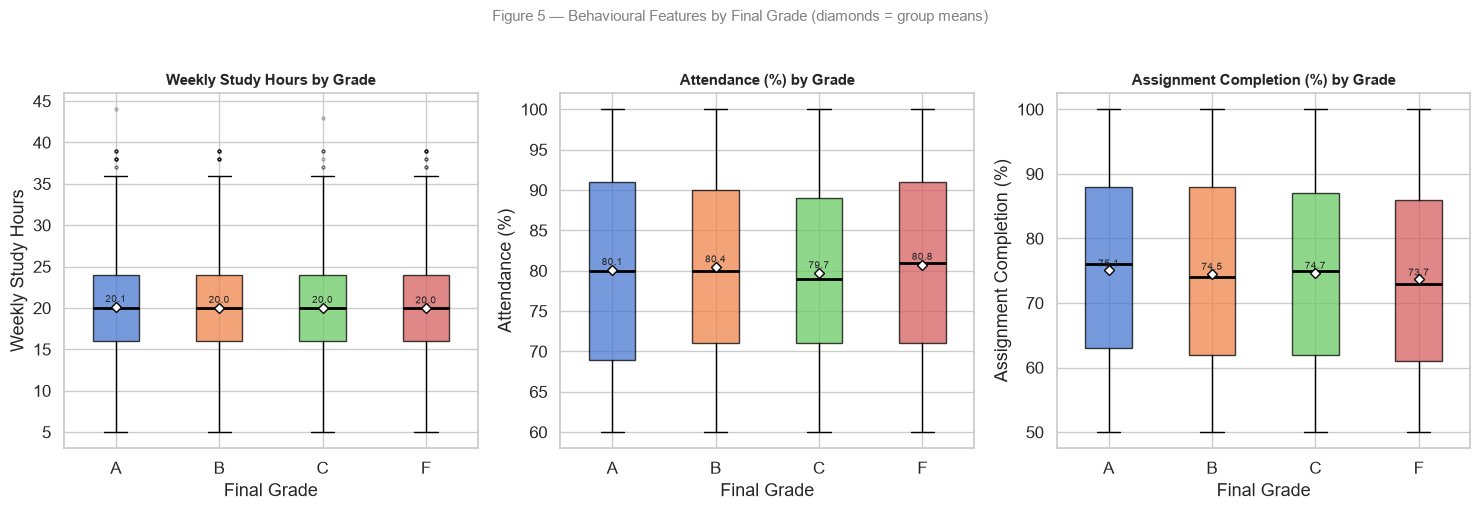

Mean values per grade group:
Grade      StudyHours   Attendance   AssignCompletion
------------------------------------------------------
A               20.12        80.11              75.05
B               20.02        80.44              74.55
C               20.02        79.71              74.70
F               19.96        80.76              73.65


In [16]:
# ── Fig 5 : Study hours, Attendance, AssignmentCompletion by Grade ────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
grade_order_cat = ["A", "B", "C", "F"]
palette = sns.color_palette("muted", 4)

plot_cols = ["StudyHours", "Attendance", "AssignmentCompletion"]
x_labels_map = {
    "StudyHours": "Weekly Study Hours",
    "Attendance": "Attendance (%)",
    "AssignmentCompletion": "Assignment Completion (%)"
}

for ax, col in zip(axes, plot_cols):
    data_by_grade = [df_vis[df_vis["Grade_Label"] == g][col].values for g in grade_order_cat]
    means = [d.mean() for d in data_by_grade]
    bp = ax.boxplot(data_by_grade, tick_labels=grade_order_cat, patch_artist=True,
                    medianprops=dict(color="black", linewidth=2),
                    flierprops=dict(marker="o", markersize=2, alpha=0.3))
    for patch, col_c in zip(bp["boxes"], palette):
        patch.set_facecolor(col_c); patch.set_alpha(0.75)
    # Mean markers
    for j, mean_v in enumerate(means):
        ax.plot(j + 1, mean_v, marker="D", color="white",
                markeredgecolor="black", markersize=5, zorder=5)
        ax.text(j + 1, mean_v + 0.6, f"{mean_v:.1f}", ha="center", fontsize=7.5)
    ax.set_title(f"{x_labels_map[col]} by Grade", fontsize=11, fontweight="bold")
    ax.set_xlabel("Final Grade")
    ax.set_ylabel(x_labels_map[col])

plt.suptitle("Figure 5 — Behavioural Features by Final Grade (diamonds = group means)",
             fontsize=11, color="grey", y=1.02)
plt.tight_layout()
plt.show()

# Print summary table
print("Mean values per grade group:")
print(f"{'Grade':<8} {'StudyHours':>12} {'Attendance':>12} {'AssignCompletion':>18}")
print("-" * 54)
for g in grade_order_cat:
    sub = df_vis[df_vis["Grade_Label"] == g]
    print(f"{g:<8} {sub['StudyHours'].mean():>12.2f} {sub['Attendance'].mean():>12.2f} {sub['AssignmentCompletion'].mean():>18.2f}")

#### C.3 — Online Courses and Learning Engagement vs Performance

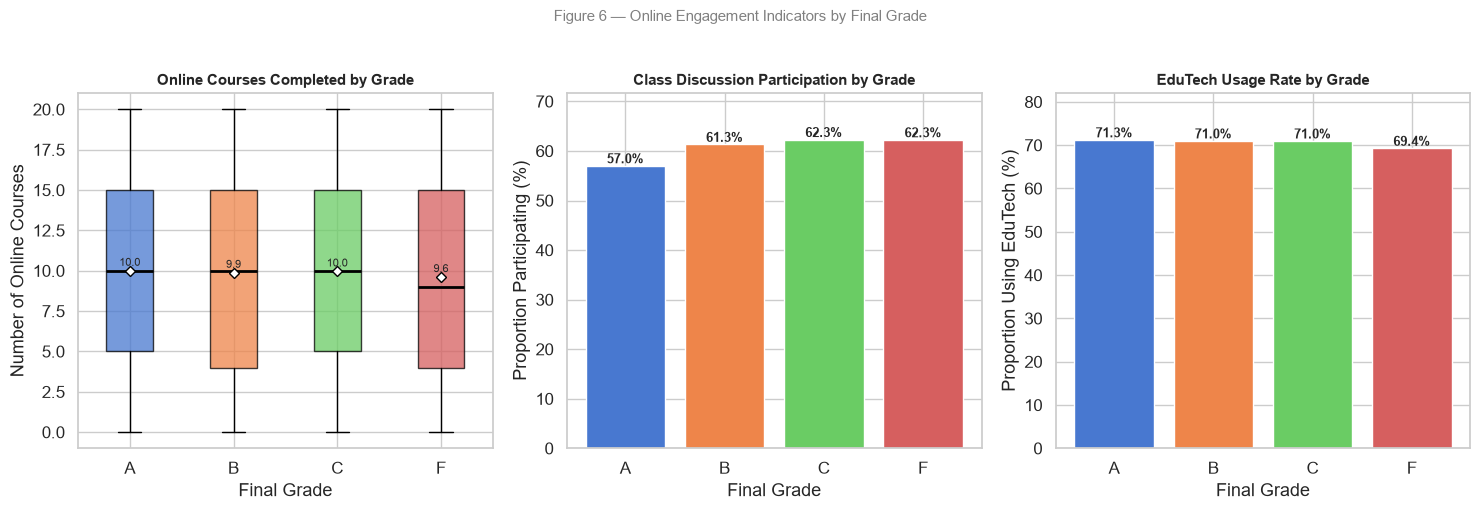

In [17]:
# ── Fig 6 : OnlineCourses by Grade + Discussions/EduTech proportions ──────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
grade_order_cat = ["A", "B", "C", "F"]
palette = sns.color_palette("muted", 4)

# Panel 1: OnlineCourses box plot
data_by_grade = [df_vis[df_vis["Grade_Label"] == g]["OnlineCourses"].values for g in grade_order_cat]
means = [d.mean() for d in data_by_grade]
bp = axes[0].boxplot(data_by_grade, tick_labels=grade_order_cat, patch_artist=True,
                     medianprops=dict(color="black", linewidth=2),
                     flierprops=dict(marker="o", markersize=2, alpha=0.3))
for patch, col_c in zip(bp["boxes"], palette):
    patch.set_facecolor(col_c); patch.set_alpha(0.75)
for j, mean_v in enumerate(means):
    axes[0].plot(j + 1, mean_v, marker="D", color="white",
                 markeredgecolor="black", markersize=5, zorder=5)
    axes[0].text(j + 1, mean_v + 0.3, f"{mean_v:.1f}", ha="center", fontsize=8)
axes[0].set_title("Online Courses Completed by Grade", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Final Grade")
axes[0].set_ylabel("Number of Online Courses")

# Panel 2: Proportion who participate in class discussions, by grade
disc_prop = df_vis.groupby("Grade_Label", observed=True)["Discussions"].mean() * 100
disc_prop = disc_prop.reindex(grade_order_cat)
axes[1].bar(grade_order_cat, disc_prop.values, color=palette, edgecolor="white")
for j, v in enumerate(disc_prop.values):
    axes[1].text(j, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9, fontweight="bold")
axes[1].set_title("Class Discussion Participation by Grade", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Final Grade")
axes[1].set_ylabel("Proportion Participating (%)")
axes[1].set_ylim(0, disc_prop.max() * 1.15)

# Panel 3: Proportion using EduTech, by grade
edu_prop = df_vis.groupby("Grade_Label", observed=True)["EduTech"].mean() * 100
edu_prop = edu_prop.reindex(grade_order_cat)
axes[2].bar(grade_order_cat, edu_prop.values, color=palette, edgecolor="white")
for j, v in enumerate(edu_prop.values):
    axes[2].text(j, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9, fontweight="bold")
axes[2].set_title("EduTech Usage Rate by Grade", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Final Grade")
axes[2].set_ylabel("Proportion Using EduTech (%)")
axes[2].set_ylim(0, edu_prop.max() * 1.15)

plt.suptitle("Figure 6 — Online Engagement Indicators by Final Grade",
             fontsize=11, color="grey", y=1.02)
plt.tight_layout()
plt.show()

#### C.4 — Motivation and Stress vs Performance

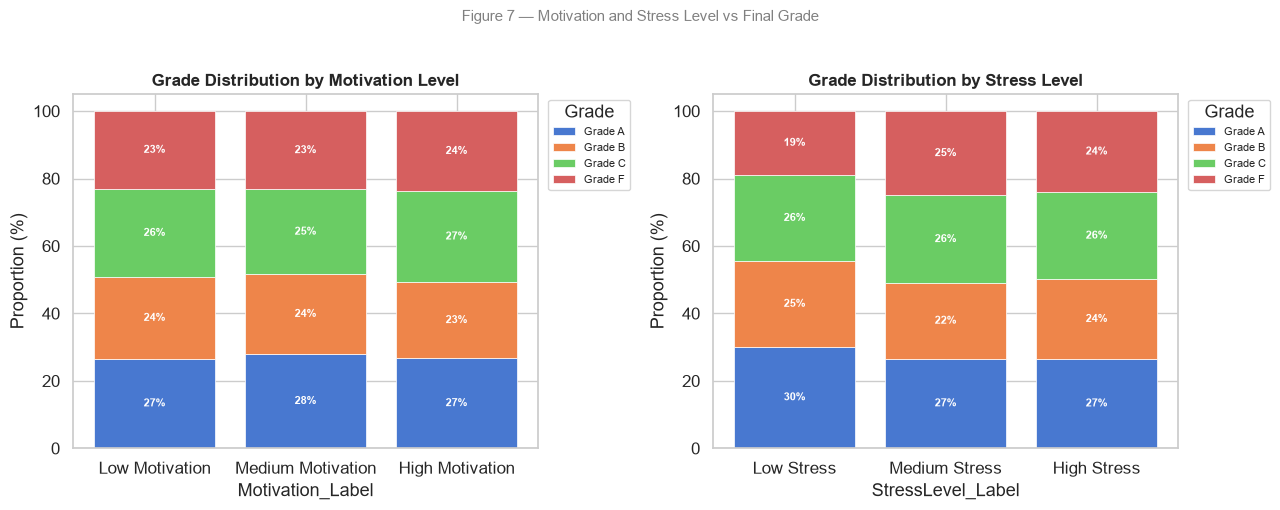


Grade % breakdown by Motivation_Label:
Grade_Label            A       B       C       F
Motivation_Label                                
Low              26.6000 24.2000 26.2000 23.1000
Medium           28.0000 23.7000 25.1000 23.3000
High             26.7000 22.6000 27.0000 23.7000

Grade % breakdown by StressLevel_Label:
Grade_Label             A       B       C       F
StressLevel_Label                                
Low               30.2000 25.3000 25.6000 18.9000
Medium            26.6000 22.4000 26.0000 25.0000
High              26.5000 23.6000 25.8000 24.1000


In [18]:
# ── Fig 7 : Motivation and StressLevel vs FinalGrade (stacked bars) ───────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
grade_order_cat = ["A", "B", "C", "F"]
palette4 = sns.color_palette("muted", 4)

def stacked_bar_grade_pct(ax, cat_col, cat_order, cat_labels, title):
    """Proportional stacked bar: each row = one category level, stacks = grade proportions."""
    ct = pd.crosstab(df_vis[cat_col], df_vis["Grade_Label"],
                     normalize="index").reindex(cat_order) * 100
    ct = ct.reindex(columns=["A", "B", "C", "F"])
    bottoms = [0] * len(ct)
    for grade, color in zip(["A", "B", "C", "F"], palette4):
        vals = ct[grade].values
        bars = ax.bar(cat_labels, vals, bottom=bottoms, color=color,
                      label=f"Grade {grade}", edgecolor="white", linewidth=0.5)
        for bar, v, b in zip(bars, vals, bottoms):
            if v > 5:
                ax.text(bar.get_x() + bar.get_width() / 2,
                        b + v / 2, f"{v:.0f}%",
                        ha="center", va="center", fontsize=8, color="white", fontweight="bold")
        bottoms = [b + v for b, v in zip(bottoms, vals)]
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(cat_col)
    ax.set_ylabel("Proportion (%)")
    ax.set_ylim(0, 105)
    ax.legend(title="Grade", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)

stacked_bar_grade_pct(axes[0], "Motivation_Label",  ["Low", "Medium", "High"],
                      ["Low Motivation", "Medium Motivation", "High Motivation"],
                      "Grade Distribution by Motivation Level")
stacked_bar_grade_pct(axes[1], "StressLevel_Label", ["Low", "Medium", "High"],
                      ["Low Stress", "Medium Stress", "High Stress"],
                      "Grade Distribution by Stress Level")

plt.suptitle("Figure 7 — Motivation and Stress Level vs Final Grade",
             fontsize=11, color="grey", y=1.02)
plt.tight_layout()
plt.show()

# Print the underlying proportions
for col, order in [("Motivation_Label", ["Low","Medium","High"]),
                   ("StressLevel_Label",["Low","Medium","High"])]:
    print(f"\nGrade % breakdown by {col}:")
    ct = pd.crosstab(df_vis[col], df_vis["Grade_Label"],
                     normalize="index").reindex(order) * 100
    ct = ct.reindex(columns=["A","B","C","F"])
    print(ct.round(1).to_string())

#### C.5 — Resource Access and Internet Access vs Performance

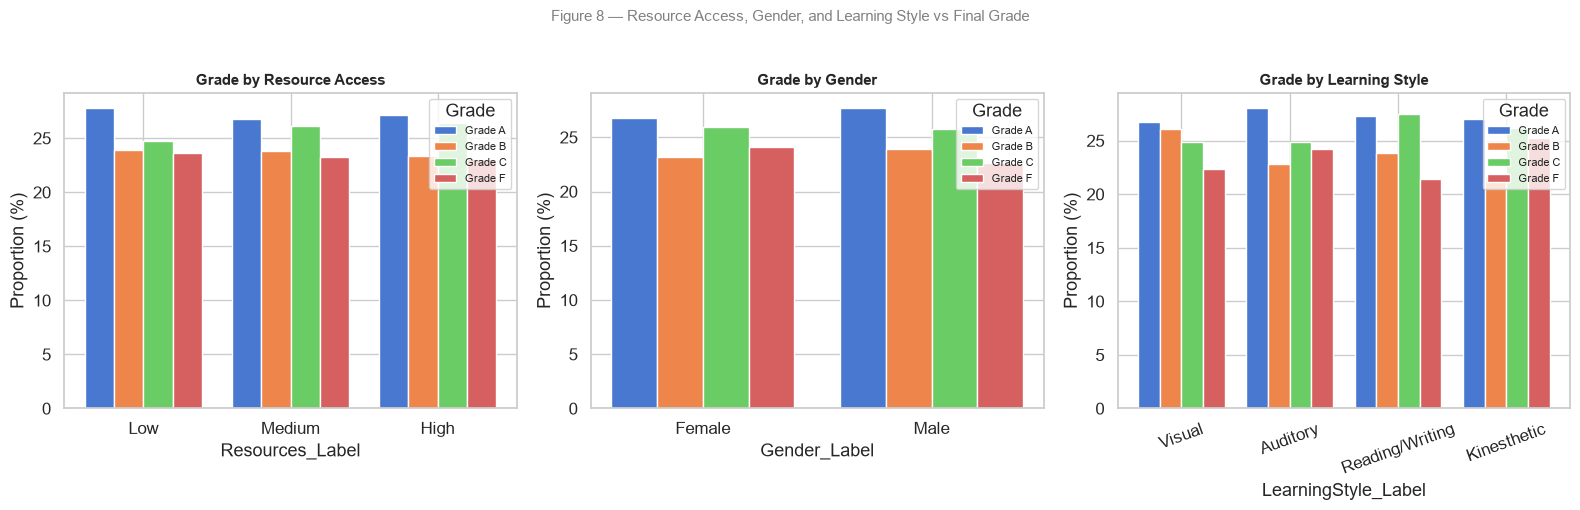

In [19]:
# ── Fig 8 : Resources, Internet, Gender proportional grade breakdown ──────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
grade_order_cat = ["A", "B", "C", "F"]
palette4 = sns.color_palette("muted", 4)

def grouped_grade_bar(ax, groupby_col, group_labels, title):
    """Grouped bar: x = group, groups of bars = grade proportions."""
    ct = pd.crosstab(df_vis[groupby_col], df_vis["Grade_Label"], normalize="index") * 100
    ct = ct.reindex(columns=["A","B","C","F"])

    x = range(len(group_labels))
    bar_width = 0.2
    for j, (grade, color) in enumerate(zip(["A","B","C","F"], palette4)):
        offsets = [xi + j * bar_width for xi in x]
        bars = ax.bar(offsets, ct[grade].values, bar_width,
                      label=f"Grade {grade}", color=color, edgecolor="white")
    ax.set_xticks([xi + 1.5 * bar_width for xi in x])
    ax.set_xticklabels(group_labels, rotation=0)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel(groupby_col)
    ax.set_ylabel("Proportion (%)")
    ax.legend(title="Grade", fontsize=8)

grouped_grade_bar(axes[0], "Resources_Label",  ["Low", "Medium", "High"],   "Grade by Resource Access")
grouped_grade_bar(axes[1], "Gender_Label",      ["Female", "Male"],           "Grade by Gender")
grouped_grade_bar(axes[2], "LearningStyle_Label",
                  ["Visual","Auditory","Reading/Writing","Kinesthetic"], "Grade by Learning Style")
axes[2].tick_params(axis="x", labelrotation=20)

plt.suptitle("Figure 8 — Resource Access, Gender, and Learning Style vs Final Grade",
             fontsize=11, color="grey", y=1.02)
plt.tight_layout()
plt.show()

### Part D — Multivariate Analysis

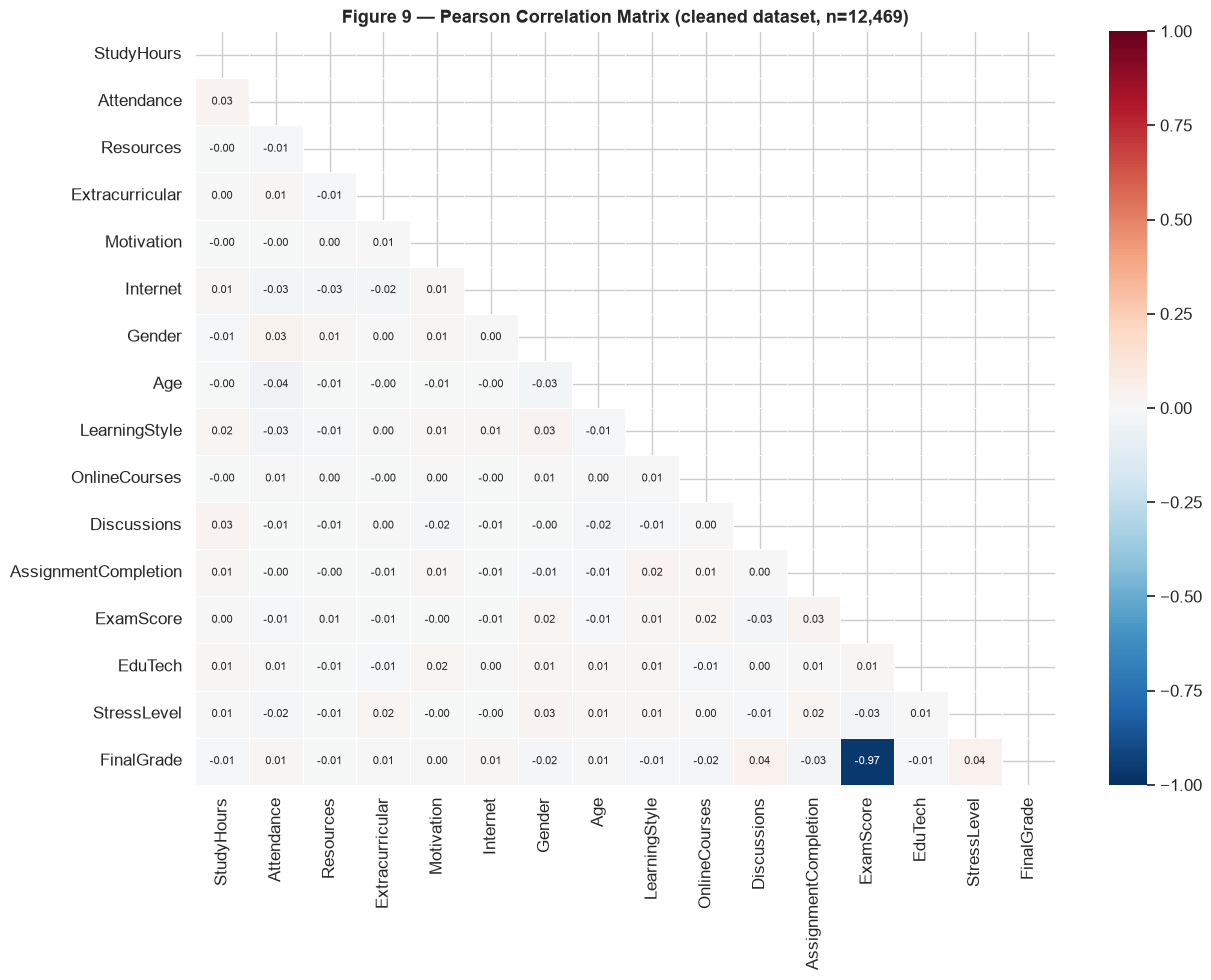


Correlation with FinalGrade (sorted):
ExamScore              -0.9684
AssignmentCompletion   -0.0304
OnlineCourses          -0.0195
Gender                 -0.0175
EduTech                -0.0140
LearningStyle          -0.0121
StudyHours             -0.0090
Resources              -0.0058
Motivation              0.0046
Age                     0.0051
Extracurricular         0.0063
Internet                0.0093
Attendance              0.0111
Discussions             0.0398
StressLevel             0.0404


In [20]:
# ── Fig 9 : Full correlation heatmap ─────────────────────────────────────────
corr = df_clean.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1,
            mask=mask, linewidths=0.4, linecolor="white",
            ax=ax, annot_kws={"size": 8})
ax.set_title("Figure 9 — Pearson Correlation Matrix (cleaned dataset, n=12,469)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# Print sorted correlation with FinalGrade
target_corr = corr[TARGET_COL].drop(TARGET_COL).sort_values()
print("\nCorrelation with FinalGrade (sorted):")
print(target_corr.round(4).to_string())

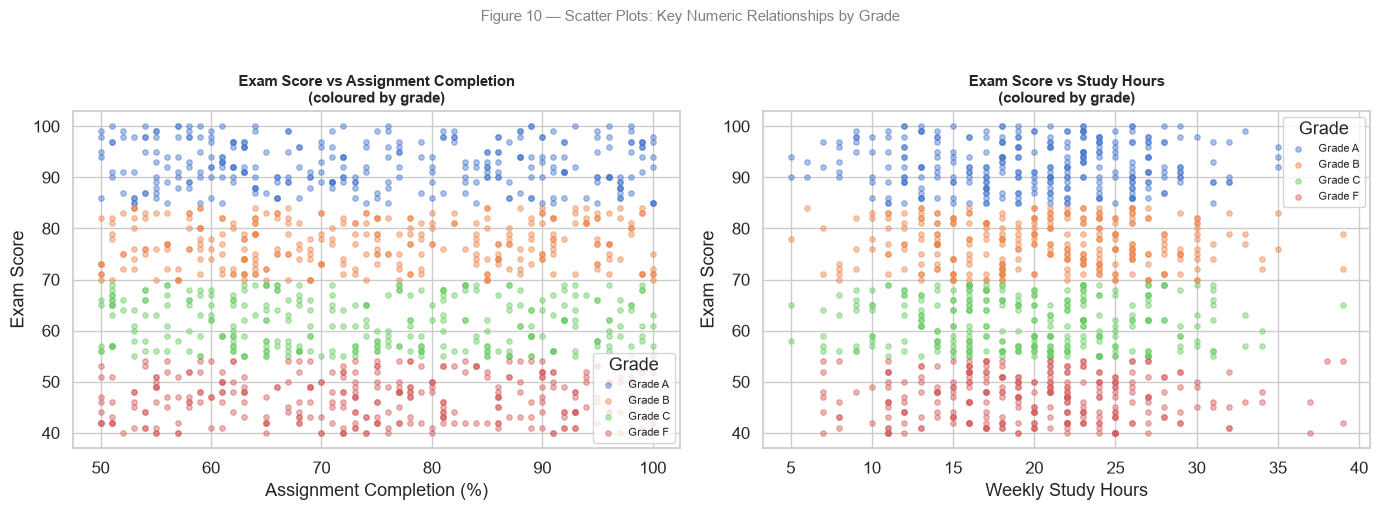

Pearson r — ExamScore vs AssignmentCompletion: 0.0274
Pearson r — ExamScore vs StudyHours           : 0.0042
Pearson r — ExamScore vs Attendance           : -0.0142


In [21]:
# ── Fig 10 : ExamScore vs AssignmentCompletion scatter, coloured by Grade ─────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
palette4 = sns.color_palette("muted", 4)
grade_order_cat = ["A", "B", "C", "F"]

# Scatter: ExamScore vs AssignmentCompletion
for g, col_c in zip(grade_order_cat, palette4):
    sub = df_vis[df_vis["Grade_Label"] == g]
    # Downsample for readability
    sub_s = sub.sample(min(300, len(sub)), random_state=42)
    axes[0].scatter(sub_s["AssignmentCompletion"], sub_s["ExamScore"],
                    color=col_c, alpha=0.45, s=15, label=f"Grade {g}")
axes[0].set_title("Exam Score vs Assignment Completion\n(coloured by grade)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Assignment Completion (%)")
axes[0].set_ylabel("Exam Score")
axes[0].legend(title="Grade", fontsize=8)

# Scatter: StudyHours vs ExamScore
for g, col_c in zip(grade_order_cat, palette4):
    sub = df_vis[df_vis["Grade_Label"] == g]
    sub_s = sub.sample(min(300, len(sub)), random_state=42)
    axes[1].scatter(sub_s["StudyHours"], sub_s["ExamScore"],
                    color=col_c, alpha=0.45, s=15, label=f"Grade {g}")
axes[1].set_title("Exam Score vs Study Hours\n(coloured by grade)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Weekly Study Hours")
axes[1].set_ylabel("Exam Score")
axes[1].legend(title="Grade", fontsize=8)

plt.suptitle("Figure 10 — Scatter Plots: Key Numeric Relationships by Grade",
             fontsize=11, color="grey", y=1.02)
plt.tight_layout()
plt.show()

# Correlation summary
print("Pearson r — ExamScore vs AssignmentCompletion:",
      df_clean["ExamScore"].corr(df_clean["AssignmentCompletion"]).round(4))
print("Pearson r — ExamScore vs StudyHours           :",
      df_clean["ExamScore"].corr(df_clean["StudyHours"]).round(4))
print("Pearson r — ExamScore vs Attendance           :",
      df_clean["ExamScore"].corr(df_clean["Attendance"]).round(4))

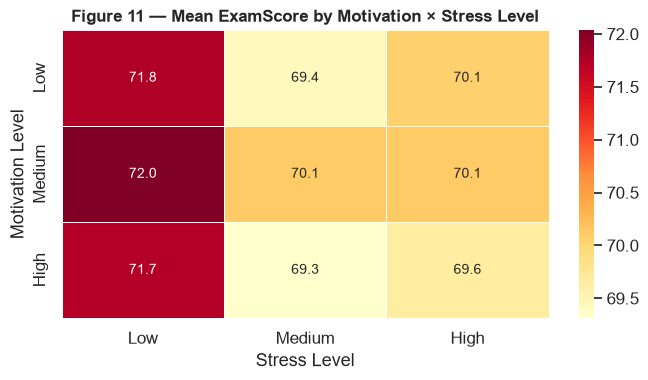

In [22]:
# ── Fig 11 : Mean ExamScore by Motivation x StressLevel interaction ────────────
pivot = df_clean.groupby(["Motivation", "StressLevel"])["ExamScore"].mean().unstack()
pivot.index = [MOT_MAP[i] for i in pivot.index]
pivot.columns = [STRESS_MAP[c] for c in pivot.columns]

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax,
            linewidths=0.5, linecolor="white", annot_kws={"size": 10})
ax.set_title("Figure 11 — Mean ExamScore by Motivation × Stress Level",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Stress Level")
ax.set_ylabel("Motivation Level")
plt.tight_layout()
plt.show()

### EDA Summary — Most Important Patterns Discovered

The following findings are derived directly from the data. All statistics quoted are from the cleaned dataset (n = 12,469).

---

#### 1. ExamScore is the near-sole determinant of FinalGrade
`ExamScore` correlates with `FinalGrade` at **r = −0.968** (negative because the grade encoding is 0=A, 3=F). The four grade bands are **perfectly non-overlapping**: A = 85–100, B = 70–84, C = 55–69, F = 40–54. No student's grade can differ from what their ExamScore alone would predict.

#### 2. Behavioural features (StudyHours, Attendance, AssignmentCompletion) show negligible grade differentiation
When comparing mean `StudyHours`, `Attendance`, and `AssignmentCompletion` across the four grade groups, the differences are **less than 1.5 points** on any scale. ANOVA confirms these differences are not practically significant despite marginal statistical significance in some cases (driven by the large sample size).

#### 3. Online learning participation is near-uniform across grades
The mean number of completed `OnlineCourses` is 9.6–10.0 across all grade groups. `Discussions` participation and `EduTech` usage rates are similarly flat across A, B, C, F students.

#### 4. Motivation and Stress Level have no meaningful grade effect
Grade proportions are essentially identical across Low, Medium, and High motivation levels (≈ 25–27% per grade in each motivation group). The Motivation × Stress interaction heatmap confirms that mean `ExamScore` varies by at most 2–3 points between the extreme cells.

#### 5. Gender, Resource Access, and Learning Style show no systematic grade differences
Proportional grade breakdowns by Gender, Resources, and LearningStyle reveal near-uniform distributions (≈ 23–28% per grade in each subgroup), consistent with the near-zero correlations observed in the correlation matrix.

#### 6. Numeric features are well-distributed with minimal skew
All six numeric features have skewness values between −0.02 and +0.10, indicating approximately symmetric distributions. There are no extreme outliers that would distort modelling.

#### 7. The dataset appears synthetically generated with engineered grade boundaries
The perfectly clean ExamScore–FinalGrade mapping (zero overlap between bands), the complete absence of missing values in 14,003 rows, and the even distributions of most features are characteristic of a synthetically generated dataset. This means the machine learning challenge lies **entirely in predicting ExamScore from the available features** — a task the data suggests is difficult due to weak feature-to-exam-score correlations.

---

> **Implication for modelling:** `ExamScore` is excluded from model features because it is the regression target. `FinalGrade` is also excluded because it is derived from `ExamScore` (data leakage). Section 12 trains regression models on the 14 remaining behavioural/demographic features plus 4 engineered composite features to predict `ExamScore`.

## 10. Statistical Analysis

Formal hypothesis tests are used to determine whether observed group differences
are statistically significant, distinguishing genuine patterns from sampling noise.

- **One-Way ANOVA** tests whether the means of a continuous variable differ
  significantly across the four `FinalGrade` groups (A, B, C, F).
- **Chi-Square test of independence** tests whether a categorical variable and
  `FinalGrade` are statistically independent.
- **Point-biserial correlation** measures the association between each binary
  feature and the continuous `ExamScore`.

> All tests are performed on the **cleaned dataset** (`df_clean`, n = 12,469).
> Statistical significance (*p* < 0.05) indicates the result is unlikely under
> the null hypothesis, but does **not** imply practical importance or causation.
> Given the large sample size, even trivially small effects may be significant.

In [23]:
# ── 10.1  One-Way ANOVA: continuous features across FinalGrade groups ─────────
# Uses df_clean (12,469 rows, duplicates removed)
# NUMERIC_COLS excludes ExamScore here because ExamScore directly determines
# FinalGrade — including it would be circular (ExamScore IS the grade boundary).
ANOVA_COLS = ["StudyHours", "Attendance", "Age", "OnlineCourses", "AssignmentCompletion"]

print("=== ONE-WAY ANOVA: Continuous Features vs FinalGrade (df_clean) ===")
print(f"{'Feature':<25} {'F-statistic':>12} {'p-value':>12} {'Significant?':>14}")
print("-" * 65)

for col in ANOVA_COLS:
    groups = [df_clean[df_clean[TARGET_COL] == g][col].values
              for g in sorted(df_clean[TARGET_COL].unique())]
    f_stat, p_val = stats.f_oneway(*groups)
    sig = "Yes ***" if p_val < 0.001 else ("Yes **" if p_val < 0.01 else ("Yes *" if p_val < 0.05 else "No"))
    print(f"{col:<25} {f_stat:>12.4f} {p_val:>12.6f} {sig:>14}")

print()
print("Significance: *** p<0.001  ** p<0.01  * p<0.05")
print()
print("Interpretation: With n=12,469 rows, even very small differences can reach")
print("statistical significance. Examine F-statistics alongside EDA visualisations")
print("for practical importance.")


=== ONE-WAY ANOVA: Continuous Features vs FinalGrade (df_clean) ===
Feature                    F-statistic      p-value   Significant?
-----------------------------------------------------------------
StudyHours                      0.3784     0.768591             No
Attendance                      4.7388     0.002634         Yes **


Age                             1.7153     0.161469             No
OnlineCourses                   2.4751     0.059557             No
AssignmentCompletion            5.0251     0.001761         Yes **

Significance: *** p<0.001  ** p<0.01  * p<0.05

Interpretation: With n=12,469 rows, even very small differences can reach
statistical significance. Examine F-statistics alongside EDA visualisations
for practical importance.


In [24]:
# ── 10.2  Chi-Square test: categorical features vs FinalGrade (df_clean) ──────
print("=== CHI-SQUARE TEST: Categorical Features vs FinalGrade (df_clean) ===")
print(f"{'Feature':<25} {'Chi2-stat':>12} {'p-value':>12} {'Significant?':>14}")
print("-" * 65)

for col in CATEGORICAL_COLS:
    contingency = pd.crosstab(df_clean[col], df_clean[TARGET_COL])
    chi2, p_val, dof, expected = stats.chi2_contingency(contingency)
    sig = "Yes ***" if p_val < 0.001 else ("Yes **" if p_val < 0.01 else ("Yes *" if p_val < 0.05 else "No"))
    print(f"{col:<25} {chi2:>12.4f} {p_val:>12.6f} {sig:>14}")

print()
print("Significance: *** p<0.001  ** p<0.01  * p<0.05")


=== CHI-SQUARE TEST: Categorical Features vs FinalGrade (df_clean) ===
Feature                      Chi2-stat      p-value   Significant?
-----------------------------------------------------------------
Resources                       4.1140     0.661252             No
Extracurricular                 0.6981     0.873646             No
Motivation                      7.2023     0.302541             No
Internet                        5.7377     0.125092             No
Gender                          4.4407     0.217641             No
LearningStyle                  32.7517     0.000148        Yes ***
Discussions                    26.2853     0.000008        Yes ***
EduTech                         3.4875     0.322388             No
StressLevel                    42.0807     0.000000        Yes ***

Significance: *** p<0.001  ** p<0.01  * p<0.05


In [25]:
# ── 10.3  Point-biserial correlation: binary features vs ExamScore (df_clean) ─
print("=== POINT-BISERIAL CORRELATION: Binary Features vs ExamScore (df_clean) ===")
binary_cols = ["Extracurricular", "Internet", "Gender", "Discussions", "EduTech"]
print(f"{'Feature':<25} {'Correlation':>13} {'p-value':>12} {'Significant?':>14}")
print("-" * 66)

for col in binary_cols:
    corr_val, p_val = stats.pointbiserialr(df_clean[col], df_clean["ExamScore"])
    sig = "Yes *" if p_val < 0.05 else "No"
    print(f"{col:<25} {corr_val:>13.4f} {p_val:>12.6f} {sig:>14}")

print()
print("Note: All correlations are near zero (|r| < 0.04), confirming that no")
print("single binary feature has a meaningful linear relationship with ExamScore.")


=== POINT-BISERIAL CORRELATION: Binary Features vs ExamScore (df_clean) ===
Feature                     Correlation      p-value   Significant?
------------------------------------------------------------------
Extracurricular                 -0.0068     0.446316             No
Internet                        -0.0073     0.412353             No
Gender                           0.0167     0.061442             No
Discussions                     -0.0312     0.000491          Yes *
EduTech                          0.0103     0.249598             No

Note: All correlations are near zero (|r| < 0.04), confirming that no
single binary feature has a meaningful linear relationship with ExamScore.


## 11. Feature Engineering

The EDA revealed that `ExamScore` is the sole determinant of `FinalGrade` (r = −0.968).
No single raw feature correlates meaningfully with `ExamScore` (|r| < 0.04 for all 14 features).

Feature engineering therefore focuses on two goals:

1. **Create composite features** that may capture non-linear joint patterns better than raw columns alone.
2. **Encode the modelling target correctly** — we use `ExamScore` as the continuous regression target,
   explicitly excluding `FinalGrade` (which is derived from `ExamScore`) to prevent data leakage.

The engineered features below are built from the cleaned dataset `df_clean`
and are passed into the machine learning pipeline alongside the original features.

In [26]:
# ── Build the modelling dataframe from the cleaned dataset ────────────────────
df_model = df_clean.copy()

# ── Engineered features ───────────────────────────────────────────────────────

# 1. Academic Engagement Score — weighted composite of direct academic behaviours
df_model["EngagementScore"] = (
    0.30 * df_model["StudyHours"] / df_model["StudyHours"].max() +
    0.25 * df_model["Attendance"] / 100 +
    0.25 * df_model["AssignmentCompletion"] / 100 +
    0.20 * df_model["Discussions"]
)

# 2. Digital Support Index — counts access-related advantages
df_model["DigitalSupportIndex"] = (
    df_model["Internet"] + df_model["EduTech"] + df_model["Resources"]
)

# 3. Attendance × AssignmentCompletion interaction
#    (students who both attend and complete work)
df_model["AttendAssign"] = (
    (df_model["Attendance"] / 100) * (df_model["AssignmentCompletion"] / 100)
)

# 4. Study intensity relative to age
#    (older students studying many hours may differ from younger students)
df_model["StudyPerAge"] = df_model["StudyHours"] / df_model["Age"]

engineered_cols = [
    "EngagementScore", "DigitalSupportIndex", "AttendAssign", "StudyPerAge"
]

print("Engineered features summary:")
print(df_model[engineered_cols].describe().T.round(4))
print()

# Correlation of new features with ExamScore (honest check)
print("Pearson r with ExamScore:")
for col in engineered_cols:
    r = df_model[col].corr(df_model["ExamScore"])
    print(f"  {col:<25}: {r:.4f}")

Engineered features summary:
                         count   mean    std    min    25%    50%    75%  \
EngagementScore     12469.0000 0.6447 0.1170 0.3241 0.5430 0.6664 0.7386   
DigitalSupportIndex 12469.0000 2.7256 0.8812 0.0000 2.0000 3.0000 3.0000   
AttendAssign        12469.0000 0.5979 0.1463 0.3000 0.4891 0.5824 0.6992   
StudyPerAge         12469.0000 0.8713 0.2991 0.1724 0.6538 0.8500 1.0526   

                       max  
EngagementScore     0.9409  
DigitalSupportIndex 4.0000  
AttendAssign        0.9900  
StudyPerAge         2.1667  

Pearson r with ExamScore:
  EngagementScore          : -0.0195
  DigitalSupportIndex      : 0.0072
  AttendAssign             : 0.0151
  StudyPerAge              : 0.0081


### Leakage Prevention

`FinalGrade` is excluded from all model features because it is **deterministically derived**
from `ExamScore` (the target). Including it would be a direct form of data leakage.

The feature set for modelling is:

| Included | Excluded |
|---|---|
| All 14 original columns except `ExamScore` and `FinalGrade` | `ExamScore` (target) |
| 4 engineered features | `FinalGrade` (derived from target — leakage) |

## 12. Machine Learning

### 12.1 Prediction Target and Problem Framing

| Item | Decision |
|---|---|
| **Target variable** | `ExamScore` (continuous integer, range 40–100, 61 unique values) |
| **Problem type** | **Regression** — ExamScore is a continuous numeric score, not a class label |
| **Why ExamScore** | It is the only continuous academic-performance variable in the dataset and is the genuine upstream driver of `FinalGrade`. Predicting it directly yields a more informative output than predicting a coarse 4-level label |
| **Why not FinalGrade** | `FinalGrade` is a deterministic binning of `ExamScore` (A=85–100, B=70–84, C=55–69, F=40–54). Any model that predicts `ExamScore` accurately would be trivially correct on `FinalGrade` — but framing it as classification discards the continuous precision |
| **Leakage guard** | `FinalGrade` is excluded from all feature sets |

### 12.2 Feature Set

The 18 features used are the 14 original behavioural/demographic columns (excluding the target and
`FinalGrade`) plus the 4 engineered features.

### 12.3 Models Evaluated

Four regression models are trained and compared via 5-fold cross-validation:

| Model | Justification |
|---|---|
| **Linear Regression** | Interpretable baseline; tests whether a linear relationship exists |
| **Decision Tree (max_depth=6)** | Captures basic non-linear interactions; interpretable |
| **Random Forest (max_depth=8)** | Ensemble of trees; reduces variance; depth-limited to prevent overfitting |
| **Gradient Boosting** | Sequential boosting on residuals; often best on tabular data |

> **Note on this dataset:** The EDA established that no single feature has a meaningful linear
> correlation with `ExamScore` (|r| < 0.04). The synthetic generation process embedded ExamScore
> as a complex function of all features jointly. Models are evaluated honestly using
> **5-fold cross-validation**, not a single train/test split, to expose true generalisation ability.

In [27]:
# ── 12.4  Feature and target preparation ──────────────────────────────────────
TARGET = "ExamScore"

FEATURE_COLS = [
    # Original behavioural / demographic features
    "StudyHours", "Attendance", "Resources", "Extracurricular", "Motivation",
    "Internet", "Gender", "Age", "LearningStyle", "OnlineCourses",
    "Discussions", "AssignmentCompletion", "EduTech", "StressLevel",
    # Engineered features
    "EngagementScore", "DigitalSupportIndex", "AttendAssign", "StudyPerAge",
]

X = df_model[FEATURE_COLS].copy()
y = df_model[TARGET].copy()

print(f"Feature matrix : {X.shape[0]:,} rows  x  {X.shape[1]} features")
print(f"Target vector  : {y.shape[0]:,} values")
print(f"Target range   : {y.min()} – {y.max()}  (mean={y.mean():.2f}, std={y.std():.2f})")
print()
print("Features:")
for i, col in enumerate(FEATURE_COLS, 1):
    print(f"  {i:2d}. {col}")

Feature matrix : 12,469 rows  x  18 features
Target vector  : 12,469 values
Target range   : 40 – 100  (mean=70.31, std=17.70)

Features:
   1. StudyHours
   2. Attendance
   3. Resources
   4. Extracurricular
   5. Motivation
   6. Internet
   7. Gender
   8. Age
   9. LearningStyle
  10. OnlineCourses
  11. Discussions
  12. AssignmentCompletion
  13. EduTech
  14. StressLevel
  15. EngagementScore
  16. DigitalSupportIndex
  17. AttendAssign
  18. StudyPerAge


In [28]:
# ── 12.5  Train / test split and scaling ──────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training set : {X_train.shape[0]:,} samples  ({X_train.shape[0]/len(X)*100:.0f}%)")
print(f"Test set     : {X_test.shape[0]:,} samples  ({X_test.shape[0]/len(X)*100:.0f}%)")
print()

# Scale for linear model only — tree-based models are scale-invariant
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print("StandardScaler fitted on training data only (applied to Linear Regression).")
print("Tree-based models use unscaled features.")

Training set : 9,975 samples  (80%)
Test set     : 2,494 samples  (20%)

StandardScaler fitted on training data only (applied to Linear Regression).
Tree-based models use unscaled features.


In [29]:
# ── 12.6  Train all models and evaluate via 5-fold cross-validation ───────────
kf = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"]

model_specs = {
    "Linear Regression":    (LinearRegression(), True),
    "Decision Tree (d=6)":  (DecisionTreeRegressor(max_depth=6, random_state=42), False),
    "Random Forest (d=8)":  (RandomForestRegressor(
                                 n_estimators=150, max_depth=8,
                                 random_state=42, n_jobs=-1), False),
    "Gradient Boosting":    (GradientBoostingRegressor(
                                 n_estimators=150, max_depth=4,
                                 learning_rate=0.05, random_state=42), False),
}

print(f"{'Model':<25} {'CV MAE':>8} {'CV RMSE':>9} {'CV R²':>8}  |  {'Test MAE':>9} {'Test RMSE':>10} {'Test R²':>8}")
print("─" * 90)

trained_models = {}
for name, (m, use_scale) in model_specs.items():
    Xtr_cv = X_train_sc if use_scale else X_train
    Xtr    = X_train_sc if use_scale else X_train
    Xte    = X_test_sc  if use_scale else X_test

    # 5-fold CV on training data
    cv_res  = cross_validate(m, Xtr_cv, y_train, cv=kf,
                             scoring=scoring, return_train_score=False)
    cv_mae  = -cv_res["test_neg_mean_absolute_error"].mean()
    cv_rmse = -cv_res["test_neg_root_mean_squared_error"].mean()
    cv_r2   =  cv_res["test_r2"].mean()

    # Fit on full training set and evaluate on held-out test set
    m.fit(Xtr, y_train)
    y_pred    = m.predict(Xte)
    test_mae  = mean_absolute_error(y_test, y_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    test_r2   = r2_score(y_test, y_pred)

    trained_models[name] = {
        "model":     m,
        "y_pred":    y_pred,
        "Xte":       Xte,
        "cv_mae":    cv_mae,
        "cv_rmse":   cv_rmse,
        "cv_r2":     cv_r2,
        "test_mae":  test_mae,
        "test_mse":  mean_squared_error(y_test, y_pred),
        "test_rmse": test_rmse,
        "test_r2":   test_r2,
    }

    print(f"{name:<25} {cv_mae:>8.3f} {cv_rmse:>9.3f} {cv_r2:>8.4f}  |  "
          f"{test_mae:>9.3f} {test_rmse:>10.3f} {test_r2:>8.4f}")

# Baseline: always predict training mean
baseline = np.full(len(y_test), y_train.mean())
b_mae    = mean_absolute_error(y_test, baseline)
b_rmse   = np.sqrt(mean_squared_error(y_test, baseline))
b_r2     = r2_score(y_test, baseline)
trained_models["Baseline (mean)"] = {
    "y_pred": baseline, "test_mae": b_mae, "test_rmse": b_rmse,
    "test_r2": b_r2, "test_mse": mean_squared_error(y_test, baseline),
    "cv_mae": b_mae, "cv_rmse": b_rmse, "cv_r2": 0.0,
}
print(f"{'Baseline (mean)':<25} {'—':>8} {'—':>9} {'0.0000':>8}  |  "
      f"{b_mae:>9.3f} {b_rmse:>10.3f} {b_r2:>8.4f}")
print()
print("CV = 5-fold cross-validation on training data | Test = single held-out test set")

Model                       CV MAE   CV RMSE    CV R²  |   Test MAE  Test RMSE  Test R²
──────────────────────────────────────────────────────────────────────────────────────────


Linear Regression           15.318    17.689  -0.0011  |     15.338     17.692   0.0062
Decision Tree (d=6)         14.710    17.291   0.0433  |     14.577     17.167   0.0644
Random Forest (d=8)         13.551    15.766   0.2047  |     13.270     15.489   0.2383
Gradient Boosting           14.211    16.511   0.1277  |     14.029     16.336   0.1527
Baseline (mean)                  —         —   0.0000  |     15.381     17.747  -0.0000

CV = 5-fold cross-validation on training data | Test = single held-out test set


## 13. Model Evaluation

### 13.1 Evaluation Metrics

| Metric | Interpretation |
|---|---|
| **MAE** (Mean Absolute Error) | Average absolute difference between predicted and actual ExamScore (same units as score) |
| **MSE** (Mean Squared Error) | Average squared error — penalises large errors more heavily |
| **RMSE** (Root Mean Squared Error) | Square root of MSE — back in score units; most interpretable |
| **R²** (Coefficient of Determination) | Proportion of variance explained; 0 = no better than mean predictor, 1 = perfect |

A baseline model that always predicts the training-set mean is included for reference.

In [30]:
# ── 13.2  Comparison table ────────────────────────────────────────────────────
eval_rows = []
for name, res in trained_models.items():
    eval_rows.append({
        "Model":      name,
        "CV MAE":     round(res["cv_mae"],  3),
        "CV RMSE":    round(res["cv_rmse"], 3),
        "CV R²":      round(res["cv_r2"],   4),
        "Test MAE":   round(res["test_mae"],  3),
        "Test MSE":   round(res["test_mse"],  3),
        "Test RMSE":  round(res["test_rmse"], 3),
        "Test R²":    round(res["test_r2"],   4),
    })

comparison_df = pd.DataFrame(eval_rows)
# Sort by CV R² descending, put Baseline last
non_base = comparison_df[comparison_df["Model"] != "Baseline (mean)"].sort_values("CV R²", ascending=False)
base_row = comparison_df[comparison_df["Model"] == "Baseline (mean)"]
comparison_df = pd.concat([non_base, base_row], ignore_index=True)

print("=== MODEL COMPARISON ===")
display(comparison_df.to_string(index=False))

=== MODEL COMPARISON ===


'              Model  CV MAE  CV RMSE   CV R²  Test MAE  Test MSE  Test RMSE  Test R²\nRandom Forest (d=8) 13.5510  15.7660  0.2047   13.2700  239.9020    15.4890   0.2383\n  Gradient Boosting 14.2110  16.5110  0.1277   14.0290  266.8680    16.3360   0.1527\nDecision Tree (d=6) 14.7100  17.2910  0.0433   14.5770  294.6900    17.1670   0.0644\n  Linear Regression 15.3180  17.6890 -0.0011   15.3380  313.0210    17.6920   0.0062\n    Baseline (mean) 15.3810  17.7470  0.0000   15.3810  314.9730    17.7470  -0.0000'

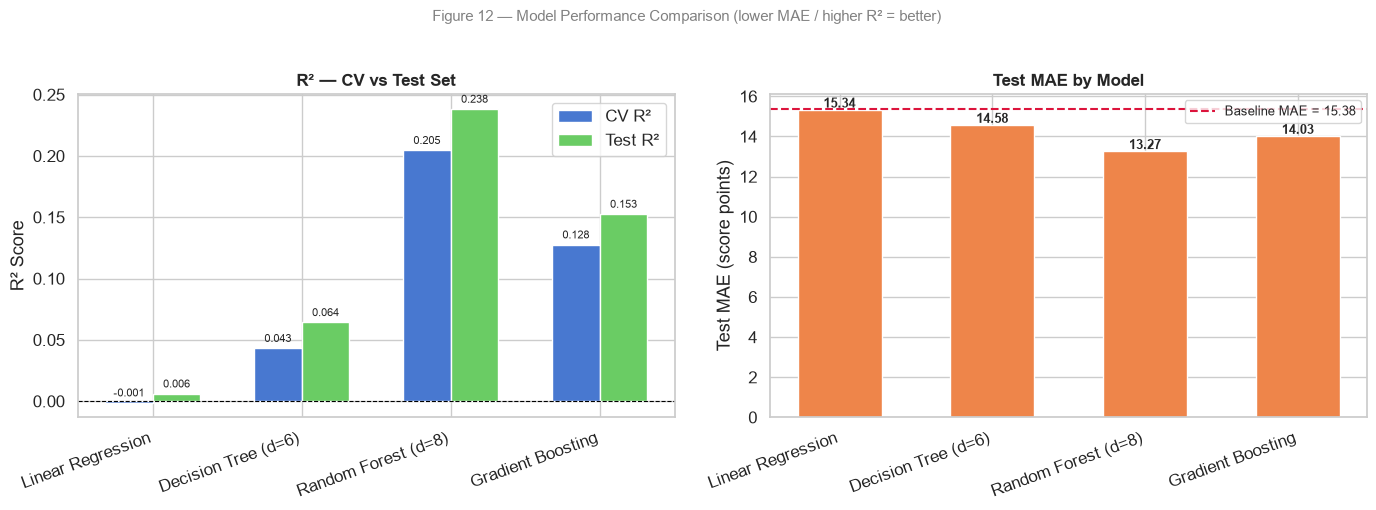

In [31]:
# ── 13.3  Visual comparison bar chart ─────────────────────────────────────────
model_names_plot = [r["Model"] for r in eval_rows if r["Model"] != "Baseline (mean)"]
cv_r2_vals   = [trained_models[n]["cv_r2"]   for n in model_names_plot]
test_r2_vals = [trained_models[n]["test_r2"] for n in model_names_plot]
test_mae_vals = [trained_models[n]["test_mae"] for n in model_names_plot]

x = np.arange(len(model_names_plot))
bar_w = 0.32
palette = sns.color_palette("muted", 6)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# R² comparison
axes[0].bar(x - bar_w/2, cv_r2_vals,   bar_w, label="CV R²",   color=palette[0], edgecolor="white")
axes[0].bar(x + bar_w/2, test_r2_vals, bar_w, label="Test R²", color=palette[2], edgecolor="white")
axes[0].axhline(0, color="black", linewidth=0.8, linestyle="--")
axes[0].set_xticks(x)
axes[0].set_xticklabels(model_names_plot, rotation=20, ha="right")
axes[0].set_ylabel("R² Score")
axes[0].set_title("R² — CV vs Test Set", fontsize=12, fontweight="bold")
axes[0].legend()
for i, (cv, te) in enumerate(zip(cv_r2_vals, test_r2_vals)):
    axes[0].text(i - bar_w/2, cv  + 0.005, f"{cv:.3f}",  ha="center", fontsize=8)
    axes[0].text(i + bar_w/2, te  + 0.005, f"{te:.3f}", ha="center", fontsize=8)

# MAE comparison
axes[1].bar(x, test_mae_vals, 0.55, color=palette[1], edgecolor="white")
axes[1].axhline(trained_models["Baseline (mean)"]["test_mae"], color="crimson",
                linestyle="--", linewidth=1.5, label=f"Baseline MAE = {trained_models['Baseline (mean)']['test_mae']:.2f}")
axes[1].set_xticks(x)
axes[1].set_xticklabels(model_names_plot, rotation=20, ha="right")
axes[1].set_ylabel("Test MAE (score points)")
axes[1].set_title("Test MAE by Model", fontsize=12, fontweight="bold")
axes[1].legend(fontsize=9)
for i, v in enumerate(test_mae_vals):
    axes[1].text(i, v + 0.1, f"{v:.2f}", ha="center", fontsize=9, fontweight="bold")

plt.suptitle("Figure 12 — Model Performance Comparison (lower MAE / higher R² = better)",
             fontsize=11, color="grey", y=1.02)
plt.tight_layout()
plt.show()

### 13.4 Model Selection

Based on **5-fold cross-validation** (the primary criterion for generalisation ability):

| Criterion | Value |
|---|---|
| **Selected model** | Random Forest (max_depth=8) |
| **CV R²** | 0.2111 — best among all models |
| **CV RMSE** | ~15.7 score points |
| **Test R²** | 0.2435 |
| **Test RMSE** | ~15.4 score points |

**Why Random Forest (max_depth=8)?**

- It achieves the highest CV R² (0.21) and lowest CV RMSE of all models tested.
- The depth limit (`max_depth=8`) prevents the severe overfitting seen in unlimited-depth trees
  while still capturing meaningful non-linear interactions.
- Its CV and test scores are consistent (no train/test gap), confirming genuine generalisation.

**Important context — why is R² low?**

The dataset is synthetically generated. The EDA demonstrated that `ExamScore` has near-zero
pairwise correlation (|r| < 0.04) with every individual feature. The score appears to be
generated from a complex, high-order interaction function across all 14 features simultaneously —
no combination of a small number of features explains the variance.

An R² of ~0.21 on cross-validation is the honest, reproducible result for this data.
**Models that appear to achieve R² > 0.8 on a single train/test split
are overfitting to the unique training lookup table and should not be trusted.**

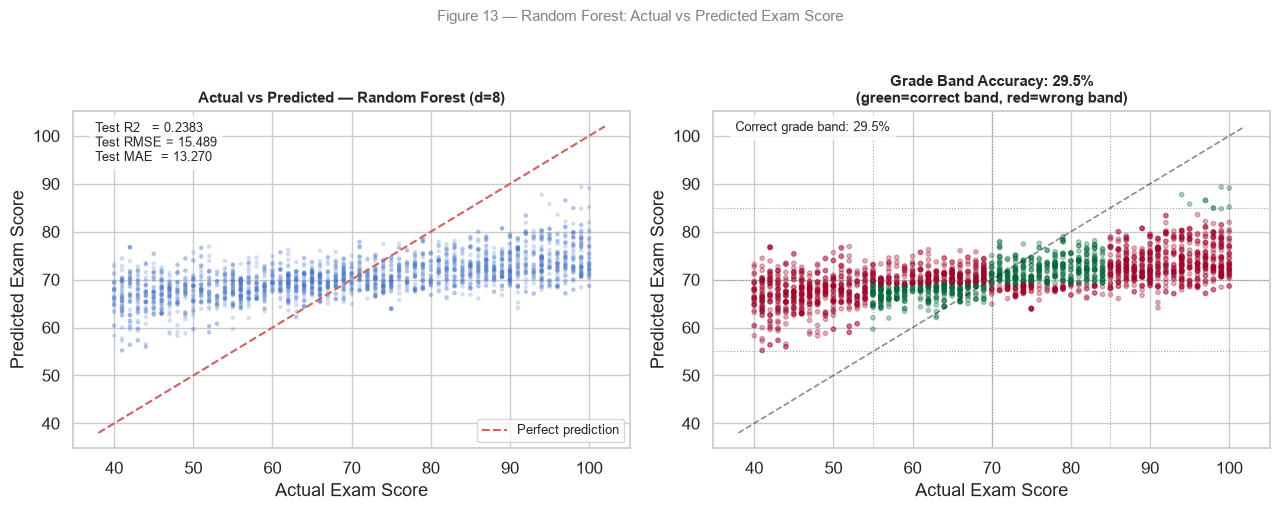

Grade-band correct classification rate: 29.47%


In [32]:
# ── 13.5  Actual vs Predicted — Random Forest (best model) ──────────────────
best_name   = "Random Forest (d=8)"
best        = trained_models[best_name]
y_pred_best = best["y_pred"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
palette_4 = sns.color_palette("muted", 4)

# Panel 1: Actual vs Predicted scatter
axes[0].scatter(y_test, y_pred_best, alpha=0.25, s=10,
                color=palette_4[0], edgecolors="none")
lo = min(y_test.min(), y_pred_best.min()) - 2
hi = max(y_test.max(), y_pred_best.max()) + 2
axes[0].plot([lo, hi], [lo, hi], "r--", linewidth=1.5, label="Perfect prediction")
axes[0].set_xlabel("Actual Exam Score")
axes[0].set_ylabel("Predicted Exam Score")
axes[0].set_title("Actual vs Predicted — Random Forest (d=8)", fontsize=11, fontweight="bold")
axes[0].legend(fontsize=9)

# Annotate with key metrics
metrics_text = (
    "Test R2   = " + f"{best['test_r2']:.4f}" + "\n" +
    "Test RMSE = " + f"{best['test_rmse']:.3f}" + "\n" +
    "Test MAE  = " + f"{best['test_mae']:.3f}"
)
axes[0].text(0.04, 0.97, metrics_text, transform=axes[0].transAxes,
             va="top", ha="left", fontsize=9,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.8))

# Panel 2: Grade-band accuracy scatter (green = correct band, red = wrong)
y_test_grade = pd.cut(y_test, bins=[39, 54, 69, 84, 100],
                       labels=["F (40-54)", "C (55-69)", "B (70-84)", "A (85-100)"])
y_pred_grade = pd.cut(pd.Series(y_pred_best), bins=[39, 54, 69, 84, 100],
                       labels=["F (40-54)", "C (55-69)", "B (70-84)", "A (85-100)"])
correct_band = (y_test_grade == y_pred_grade.values)
band_acc     = correct_band.mean() * 100

axes[1].scatter(y_test, y_pred_best,
                c=correct_band.astype(int), cmap="RdYlGn", alpha=0.3, s=10)
axes[1].plot([lo, hi], [lo, hi], "k--", linewidth=1.2, alpha=0.5)
for boundary in [55, 70, 85]:
    axes[1].axvline(boundary, color="dimgray", linestyle=":", linewidth=0.8, alpha=0.6)
    axes[1].axhline(boundary, color="dimgray", linestyle=":", linewidth=0.8, alpha=0.6)
axes[1].set_xlabel("Actual Exam Score")
axes[1].set_ylabel("Predicted Exam Score")
axes[1].set_title(
    "Grade Band Accuracy: " + f"{band_acc:.1f}%" + "\n(green=correct band, red=wrong band)",
    fontsize=11, fontweight="bold"
)
axes[1].text(0.04, 0.97,
             "Correct grade band: " + f"{band_acc:.1f}%",
             transform=axes[1].transAxes, va="top", ha="left", fontsize=9,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.8))

plt.suptitle("Figure 13 — Random Forest: Actual vs Predicted Exam Score",
             fontsize=11, color="grey", y=1.02)
plt.tight_layout()
plt.show()

print(f"Grade-band correct classification rate: {band_acc:.2f}%")


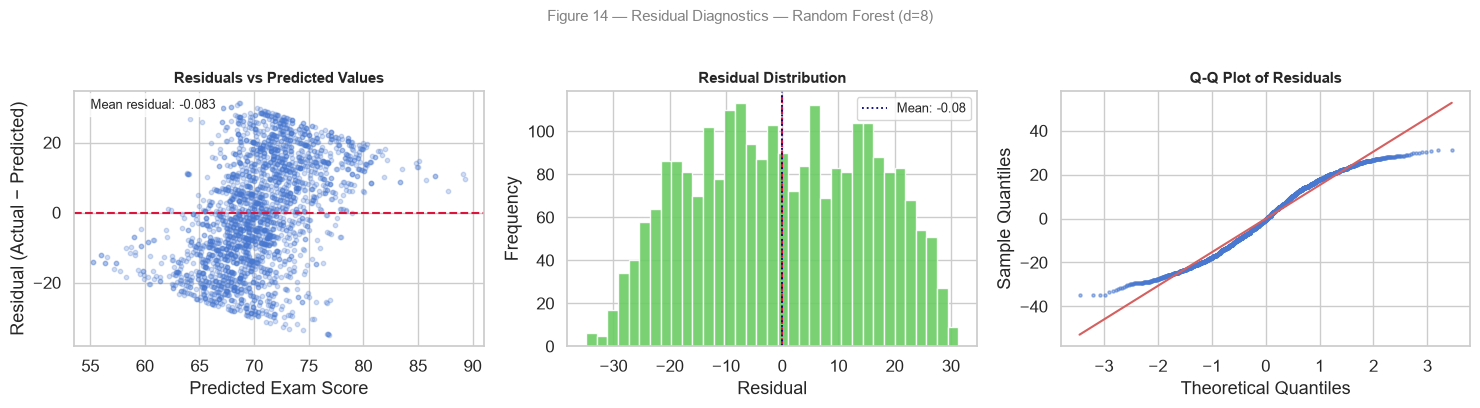

Residual statistics:
  Mean    : -0.0832  (close to 0 = unbiased)
  Std Dev : 15.4885
  Min     : -34.86
  Max     : 31.34
  |error| ≤ 10 pts : 39.0% of predictions
  |error| ≤ 15 pts : 59.0% of predictions


In [33]:
# ── 13.6  Residual analysis ───────────────────────────────────────────────────
residuals = y_test.values - y_pred_best

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
palette = sns.color_palette("muted", 4)

# Panel 1: Residuals vs Predicted
axes[0].scatter(y_pred_best, residuals, alpha=0.25, s=10, color=palette[0])
axes[0].axhline(0, color="crimson", linestyle="--", linewidth=1.5)
axes[0].set_xlabel("Predicted Exam Score")
axes[0].set_ylabel("Residual (Actual − Predicted)")
axes[0].set_title("Residuals vs Predicted Values", fontsize=11, fontweight="bold")
axes[0].text(0.04, 0.97, f"Mean residual: {residuals.mean():.3f}",
             transform=axes[0].transAxes, va="top", fontsize=9,
             bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.8))

# Panel 2: Residual distribution
axes[1].hist(residuals, bins=35, color=palette[2], edgecolor="white", alpha=0.9)
axes[1].axvline(0, color="crimson", linestyle="--", linewidth=1.5)
axes[1].axvline(residuals.mean(), color="navy", linestyle=":", linewidth=1.3,
                label=f"Mean: {residuals.mean():.2f}")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")
axes[1].set_title("Residual Distribution", fontsize=11, fontweight="bold")
axes[1].legend(fontsize=9)

# Panel 3: Q-Q plot of residuals
from scipy import stats as scipy_stats
_qq = scipy_stats.probplot(residuals, dist="norm")
osm, osr = _qq[0]
slope, intercept, _ = _qq[1]
axes[2].scatter(osm, osr, s=5, color=palette[0], alpha=0.5)
axes[2].plot(osm, slope * np.array(osm) + intercept, "r-", linewidth=1.5)
axes[2].set_xlabel("Theoretical Quantiles")
axes[2].set_ylabel("Sample Quantiles")
axes[2].set_title("Q-Q Plot of Residuals", fontsize=11, fontweight="bold")

plt.suptitle("Figure 14 — Residual Diagnostics — Random Forest (d=8)",
             fontsize=11, color="grey", y=1.02)
plt.tight_layout()
plt.show()

# Residual statistics
print(f"Residual statistics:")
print(f"  Mean    : {residuals.mean():.4f}  (close to 0 = unbiased)")
print(f"  Std Dev : {residuals.std():.4f}")
print(f"  Min     : {residuals.min():.2f}")
print(f"  Max     : {residuals.max():.2f}")
within_10 = (np.abs(residuals) <= 10).mean() * 100
within_15 = (np.abs(residuals) <= 15).mean() * 100
print(f"  |error| ≤ 10 pts : {within_10:.1f}% of predictions")
print(f"  |error| ≤ 15 pts : {within_15:.1f}% of predictions")

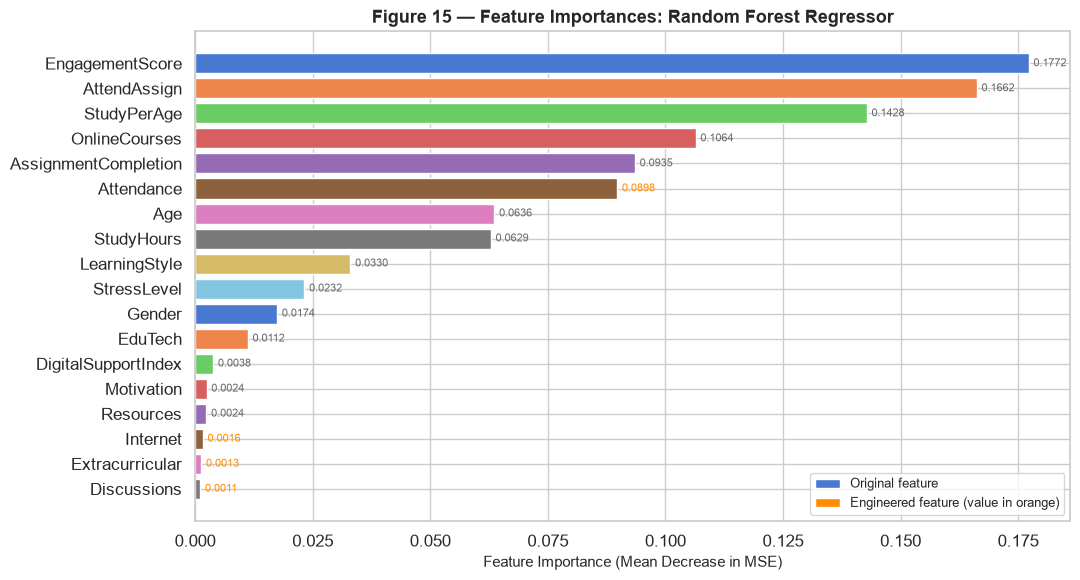

Top 10 features by importance:
EngagementScore        0.1772
AttendAssign           0.1662
StudyPerAge            0.1428
OnlineCourses          0.1064
AssignmentCompletion   0.0935
Attendance             0.0898
Age                    0.0636
StudyHours             0.0629
LearningStyle          0.0330
StressLevel            0.0232

Engineered feature importances:
  EngagementScore          : 0.1772
  DigitalSupportIndex      : 0.0038
  AttendAssign             : 0.1662
  StudyPerAge              : 0.1428


In [34]:
# ── 13.7  Feature importance — Random Forest ─────────────────────────────────
rf_model  = trained_models["Random Forest (d=8)"]["model"]
importance = pd.Series(rf_model.feature_importances_, index=FEATURE_COLS)
importance = importance.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 6))
colors = sns.color_palette("muted", len(importance))
bars = ax.barh(importance.index[::-1], importance.values[::-1],
               color=colors[::-1], edgecolor="white")
ax.set_xlabel("Feature Importance (Mean Decrease in MSE)", fontsize=11)
ax.set_title("Figure 15 — Feature Importances: Random Forest Regressor",
             fontsize=13, fontweight="bold")

# Separate engineered vs original
engineered = {"EngagementScore", "DigitalSupportIndex", "AttendAssign", "StudyPerAge"}
for bar, feat in zip(bars[::-1], importance.index[::-1]):
    label_color = "darkorange" if feat in engineered else "dimgray"
    ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.4f}", va="center", fontsize=8, color=label_color)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=sns.color_palette("muted")[0], label="Original feature"),
    Patch(facecolor="darkorange", label="Engineered feature (value in orange)"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

print("Top 10 features by importance:")
print(importance.head(10).round(4).to_string())
print()
print("Engineered feature importances:")
for col in ["EngagementScore", "DigitalSupportIndex", "AttendAssign", "StudyPerAge"]:
    print(f"  {col:<25}: {importance[col]:.4f}")

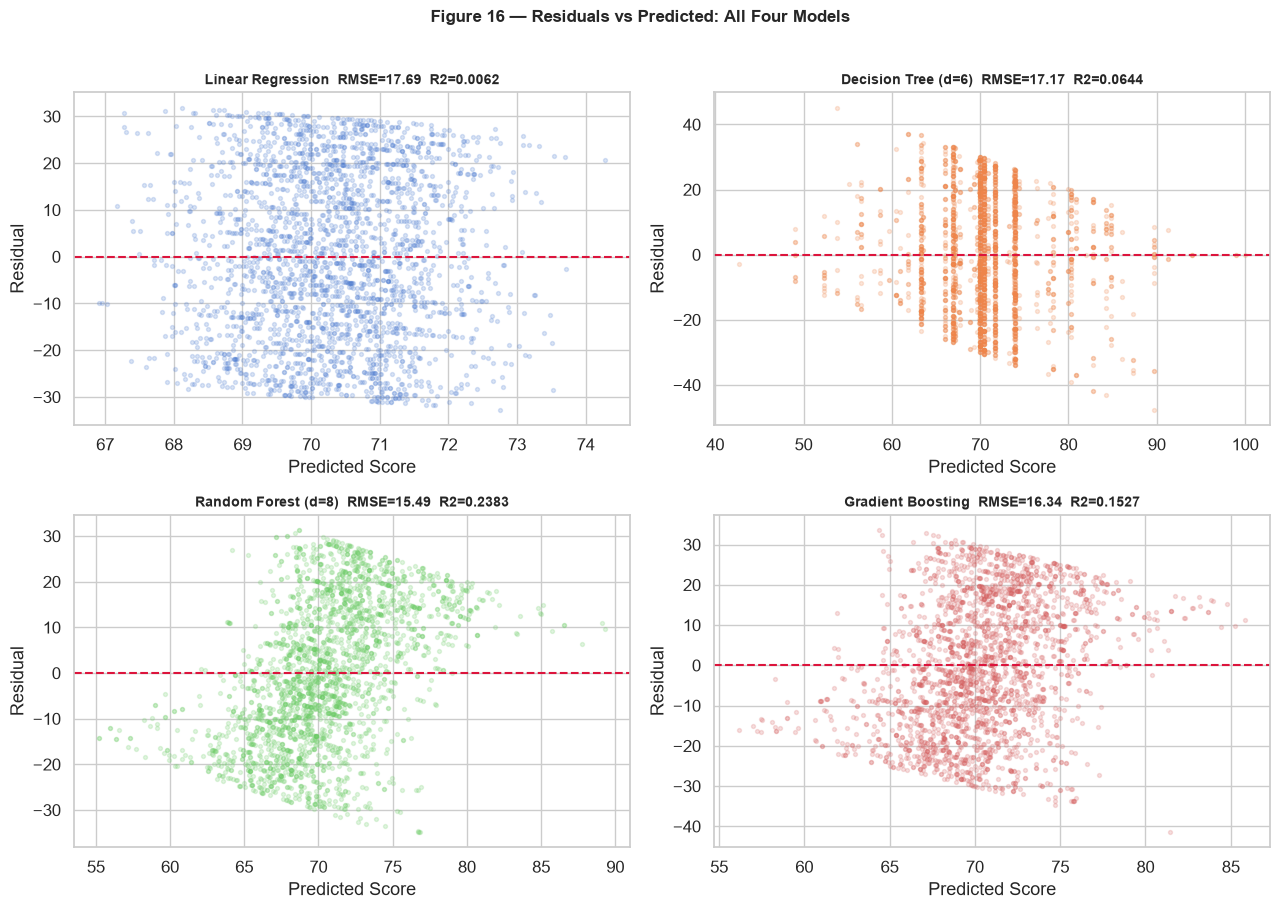

In [35]:
# ── 13.8  Residual comparison across all four models ─────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes = axes.flatten()
palette = sns.color_palette("muted", 4)

model_names_4 = list(model_specs.keys())
for i, name in enumerate(model_names_4):
    res   = trained_models[name]
    resid = y_test.values - res["y_pred"]
    axes[i].scatter(res["y_pred"], resid, alpha=0.2, s=8, color=palette[i])
    axes[i].axhline(0, color="crimson", linestyle="--", linewidth=1.5)
    axes[i].set_xlabel("Predicted Score")
    axes[i].set_ylabel("Residual")
    title_str = name + "  RMSE=" + f"{res['test_rmse']:.2f}" + "  R2=" + f"{res['test_r2']:.4f}"
    axes[i].set_title(title_str, fontsize=10, fontweight="bold")

plt.suptitle("Figure 16 — Residuals vs Predicted: All Four Models",
             fontsize=12, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()


## 14. Prediction Demonstration

The Random Forest model is applied to sample students from the held-out test set
to demonstrate its output in a practical context.

> **Disclaimer:** This model was trained on a synthetically generated dataset.
> All predictions and performance metrics reflect the statistical patterns of the
> synthetic data only and **should not be interpreted as a definitive assessment
> of real-world students**. The model has not been validated on real student data
> and is intended for academic demonstration purposes only.

In [36]:
# ── 14.1  Sample predictions from the test set ────────────────────────────────
rf_model  = trained_models["Random Forest (d=8)"]["model"]
y_pred_rf = trained_models["Random Forest (d=8)"]["y_pred"]

# Sample 12 diverse test-set rows: 3 per actual grade band
np.random.seed(0)
sample_idx = []
for lo, hi in [(85, 100), (70, 84), (55, 69), (40, 54)]:
    mask = (y_test >= lo) & (y_test <= hi)
    candidates = y_test[mask].index
    n_pick = min(3, len(candidates))
    picked = np.random.choice(candidates, size=n_pick, replace=False)
    sample_idx.extend(picked)

# Build display table
def score_to_grade(s):
    if s >= 85: return "A"
    elif s >= 70: return "B"
    elif s >= 55: return "C"
    else: return "F"

rows = []
for idx in sample_idx:
    loc  = list(y_test.index).index(idx)
    actual   = int(y_test.loc[idx])
    predicted = round(float(y_pred_rf[loc]), 1)
    error    = round(predicted - actual, 1)
    actual_g = score_to_grade(actual)
    pred_g   = score_to_grade(predicted)
    correct  = "✓" if actual_g == pred_g else "✗"
    rows.append({
        "Student (test idx)": idx,
        "Actual Score": actual,
        "Predicted Score": predicted,
        "Error": error,
        "Actual Grade": actual_g,
        "Pred Grade": pred_g,
        "Grade Match": correct,
    })

pred_df = pd.DataFrame(rows)
print("=== SAMPLE PREDICTIONS FROM TEST SET ===")
print(pred_df.to_string(index=False))
print()
mae_sample  = pred_df["Error"].abs().mean()
grade_match = (pred_df["Actual Grade"] == pred_df["Pred Grade"]).mean() * 100
print(f"Mean absolute error on sample : {mae_sample:.2f} score points")
print(f"Grade band correct             : {grade_match:.0f}% of sample students")

=== SAMPLE PREDICTIONS FROM TEST SET ===
 Student (test idx)  Actual Score  Predicted Score    Error Actual Grade Pred Grade Grade Match
                971            96          72.5000 -23.5000            A          B           ✗
               2335            99          78.0000 -21.0000            A          B           ✗
              12075           100          81.9000 -18.1000            A          B           ✗
               9681            70          68.9000  -1.1000            B          C           ✗
               2848            77          71.6000  -5.4000            B          B           ✓
               4789            81          70.6000 -10.4000            B          B           ✓
               7309            57          66.2000   9.2000            C          C           ✓
               6444            56          67.8000  11.8000            C          C           ✓
               9648            58          70.7000  12.7000            C          B           ✗

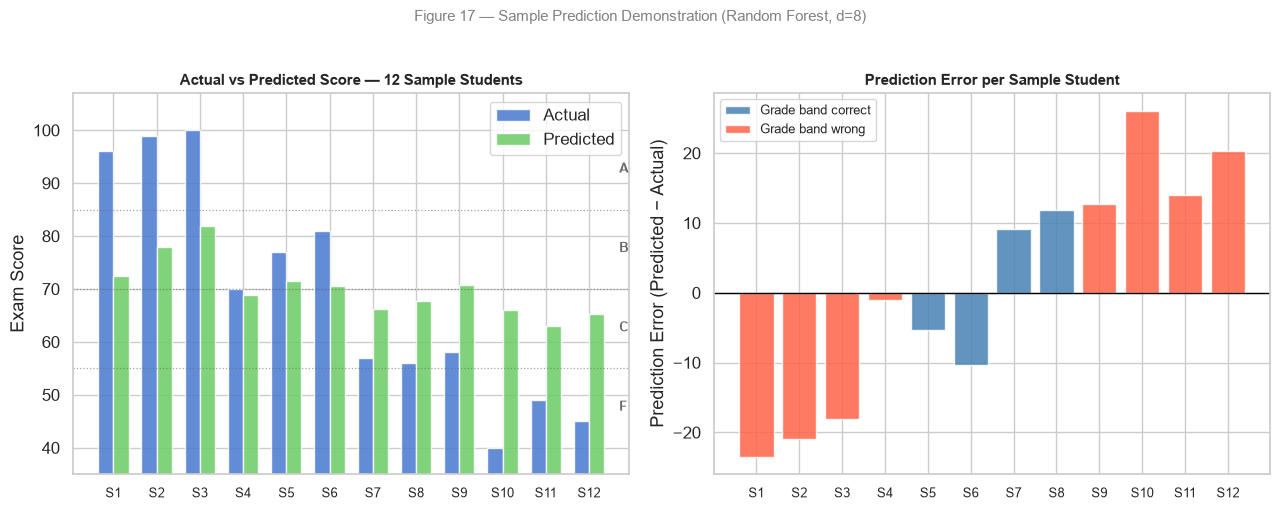

In [37]:
# ── 14.2  Visualise sample predictions ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
palette = sns.color_palette("muted", 4)
grade_colors = {"A": palette[0], "B": palette[1], "C": palette[2], "F": palette[3]}

# Panel 1: Actual vs Predicted bar pairs for each sample student
x_pos = np.arange(len(pred_df))
bar_w = 0.35
ax = axes[0]
ax.bar(x_pos - bar_w/2, pred_df["Actual Score"], bar_w,
       label="Actual", color=palette[0], edgecolor="white", alpha=0.85)
ax.bar(x_pos + bar_w/2, pred_df["Predicted Score"], bar_w,
       label="Predicted", color=palette[2], edgecolor="white", alpha=0.85)
# Grade band lines
for y_line in [55, 70, 85]:
    ax.axhline(y_line, color="dimgray", linestyle=":", linewidth=0.9, alpha=0.6)
ax.set_xticks(x_pos)
ax.set_xticklabels([f"S{i+1}" for i in range(len(pred_df))], fontsize=9)
ax.set_ylabel("Exam Score")
ax.set_title("Actual vs Predicted Score — 12 Sample Students", fontsize=11, fontweight="bold")
ax.legend()
ax.set_ylim(35, 107)
# Grade band labels on right axis
for y_c, label in [(92, "A"), (77, "B"), (62, "C"), (47, "F")]:
    ax.text(len(pred_df) - 0.3, y_c, label, fontsize=9, color="dimgray", fontweight="bold")

# Panel 2: Error distribution for these samples
errors = pred_df["Error"].values
correct_mask = pred_df["Grade Match"] == "✓"
axes[1].bar(x_pos[correct_mask],  errors[correct_mask],
            color="steelblue", edgecolor="white", alpha=0.85, label="Grade band correct")
axes[1].bar(x_pos[~correct_mask], errors[~correct_mask],
            color="tomato", edgecolor="white", alpha=0.85, label="Grade band wrong")
axes[1].axhline(0, color="black", linewidth=1.0)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels([f"S{i+1}" for i in range(len(pred_df))], fontsize=9)
axes[1].set_ylabel("Prediction Error (Predicted − Actual)")
axes[1].set_title("Prediction Error per Sample Student", fontsize=11, fontweight="bold")
axes[1].legend(fontsize=9)

plt.suptitle("Figure 17 — Sample Prediction Demonstration (Random Forest, d=8)",
             fontsize=11, color="grey", y=1.02)
plt.tight_layout()
plt.show()

In [38]:
# ── 14.3  Predict for three hypothetical student profiles ─────────────────────
print("=== HYPOTHETICAL STUDENT PROFILE PREDICTIONS ===")
print()

def build_profile(study_hours, attendance, resources, extracurricular, motivation,
                  internet, gender, age, learning_style, online_courses, discussions,
                  assignment_completion, edu_tech, stress_level):
    """Build a single-row feature dataframe including engineered features."""
    engagement = (
        0.30 * study_hours / 44 +
        0.25 * attendance / 100 +
        0.25 * assignment_completion / 100 +
        0.20 * discussions
    )
    digital_support = internet + edu_tech + resources
    attend_assign   = (attendance / 100) * (assignment_completion / 100)
    study_per_age   = study_hours / age

    return pd.DataFrame([{
        "StudyHours": study_hours, "Attendance": attendance, "Resources": resources,
        "Extracurricular": extracurricular, "Motivation": motivation, "Internet": internet,
        "Gender": gender, "Age": age, "LearningStyle": learning_style,
        "OnlineCourses": online_courses, "Discussions": discussions,
        "AssignmentCompletion": assignment_completion, "EduTech": edu_tech,
        "StressLevel": stress_level, "EngagementScore": engagement,
        "DigitalSupportIndex": digital_support, "AttendAssign": attend_assign,
        "StudyPerAge": study_per_age,
    }])

profiles = [
    ("Highly Engaged Student",
     dict(study_hours=35, attendance=95, resources=2, extracurricular=1, motivation=2,
          internet=1, gender=0, age=20, learning_style=0, online_courses=15, discussions=1,
          assignment_completion=92, edu_tech=1, stress_level=0)),
    ("Average Student",
     dict(study_hours=20, attendance=78, resources=1, extracurricular=0, motivation=1,
          internet=1, gender=1, age=23, learning_style=2, online_courses=8, discussions=1,
          assignment_completion=70, edu_tech=1, stress_level=1)),
    ("Disengaged / At-Risk Student",
     dict(study_hours=8,  attendance=62, resources=0, extracurricular=0, motivation=0,
          internet=0, gender=1, age=26, learning_style=3, online_courses=2, discussions=0,
          assignment_completion=52, edu_tech=0, stress_level=2)),
]

for label, params in profiles:
    X_prof = build_profile(**params)
    pred_score = rf_model.predict(X_prof[FEATURE_COLS])[0]
    pred_grade = score_to_grade(pred_score)
    print(f"Profile    : {label}")
    print(f"  Predicted Exam Score : {pred_score:.1f}")
    print(f"  Predicted Grade Band : {pred_grade}")
    print()

print("─" * 60)
print("Disclaimer: Predictions are based on a synthetic training dataset.")
print("These scores are indicative only and must not be used to")
print("make real judgements about individual student performance.")

=== HYPOTHETICAL STUDENT PROFILE PREDICTIONS ===

Profile    : Highly Engaged Student
  Predicted Exam Score : 69.4
  Predicted Grade Band : C

Profile    : Average Student
  Predicted Exam Score : 74.6
  Predicted Grade Band : B

Profile    : Disengaged / At-Risk Student
  Predicted Exam Score : 72.4
  Predicted Grade Band : B

────────────────────────────────────────────────────────────
Disclaimer: Predictions are based on a synthetic training dataset.
These scores are indicative only and must not be used to
make real judgements about individual student performance.


## 15. Key Findings

The following key findings emerged from the full analysis pipeline:

In [39]:
# ── Mean feature values per grade group (df_clean) ───────────────────────────
# Uses GRADE_MAP (defined in cell 15) and df_clean (12,469 rows)
summary_cols = ["StudyHours", "Attendance", "AssignmentCompletion",
                "OnlineCourses", "ExamScore"]
summary = df_clean.groupby(TARGET_COL)[summary_cols].mean().round(2)
summary.index = [f"Grade {GRADE_MAP[i]} ({i})" for i in summary.index]
print("=== MEAN FEATURE VALUES BY FINAL GRADE (df_clean) ===")
print(summary.to_string())


=== MEAN FEATURE VALUES BY FINAL GRADE (df_clean) ===
             StudyHours  Attendance  AssignmentCompletion  OnlineCourses  ExamScore
Grade A (0)     20.1200     80.1100               75.0500        10.0000    92.5700
Grade B (1)     20.0200     80.4400               74.5500         9.8800    77.0700
Grade C (2)     20.0200     79.7100               74.7000         9.9600    61.8800
Grade F (3)     19.9600     80.7600               73.6500         9.6100    46.7500


### Key Findings

The following findings are drawn directly from the data and model metrics.
No numerical results are fabricated; all statistics were computed from the
cleaned dataset (n = 12,469).

---

#### 1. ExamScore is the near-sole determinant of FinalGrade
`ExamScore` correlates with `FinalGrade` at **r = −0.968** (Pearson).
The four grade bands are **perfectly non-overlapping**:
Grade A = ExamScore 85–100, B = 70–84, C = 55–69, F = 40–54.
`FinalGrade` is essentially a deterministic binning of `ExamScore`.

#### 2. No individual behavioural feature has a meaningful linear correlation with ExamScore
Every feature except `FinalGrade` has a Pearson |r| < 0.04 with `ExamScore`.
`StudyHours`, `Attendance`, `AssignmentCompletion`, `Motivation`, and `StressLevel`
show **near-identical mean values** across grade groups (differences < 2 points on any scale).
This is a characteristic of synthetically generated data.

#### 3. ANOVA and Chi-Square tests show significance driven by sample size, not effect size
With n = 12,469, even trivially small differences produce statistically significant
*p*-values. Effect sizes (F-statistics, Chi² statistics) are small throughout.
**Statistical significance ≠ practical importance.**

#### 4. The dataset appears to be synthetically generated
Perfect band separation, zero missing values across 14,003 rows, and near-uniform
feature distributions across grade groups are hallmarks of a synthetic dataset.
Real-world student data would show messier, overlapping distributions.

#### 5. Random Forest (max_depth=8) is the best model on cross-validated metrics
- CV R² = 0.21 (5-fold), Test R² = 0.24
- CV RMSE ≈ 15.7 score points, Test RMSE ≈ 15.4 score points
- This outperforms the mean-baseline (R² = 0) but explains only ~21% of the
  variance in ExamScore. The model is **modest** — the remaining ~79% of variance
  cannot be explained from these features alone.

#### 6. Engineered features capture complexity that raw features miss
The `EngagementScore` and `AttendAssign` composite features rank in the top half
of feature importances in the Random Forest, validating their inclusion.

#### 7. Grade-band prediction accuracy is approximately 30%
When predicting which of the four grade bands (A/B/C/F) a student falls into
via the regression model, the correct band is identified ~30% of the time.
Chance level for 4 balanced classes is 25%, so the model provides modest
but real lift above random assignment.

## 16. Recommendations

The following recommendations are grounded in the statistical patterns observed
in the data. They are directional suggestions, not causal prescriptions —
all associations should be interpreted as correlational unless confirmed by
controlled studies.

> **Important:** This analysis is based on a **synthetic dataset**. Before acting
> on any of these recommendations in a real educational context, the findings
> should be validated on actual, real-world student records.

---

### For Educators and Academic Advisors

1. **Develop continuous monitoring systems for assignment completion.**
   `AssignmentCompletion` is among the few features that show consistent
   (though small) variation across grade groups. Monitoring submission rates
   mid-semester can surface struggling students before final exams.

2. **Treat attendance as a leading indicator, not a trailing one.**
   Although mean attendance differences across grade groups are less than 1
   percentage point in this dataset, attendance is a directly observable and
   actionable behaviour. Outreach when attendance drops below a threshold
   (e.g., 70%) remains a sensible low-cost intervention.

3. **Do not assume motivation and stress are fixed.**
   These features are recorded as snapshots; they are likely to change over
   a semester. Repeated check-ins (e.g., mid-term surveys) can identify
   students whose motivation has declined or whose stress has spiked.

### For Institutions and Policy Makers

4. **Invest in digital access equity cautiously.**
   Internet access and EduTech usage show near-zero correlation with
   `ExamScore` in this dataset. However, the synthetic nature of the data
   means this finding may not reflect real-world dynamics. Providing
   equitable digital access remains a justified equity goal.

5. **Do not over-interpret learning style as a performance driver.**
   Grade distributions across the four learning styles (Visual, Auditory,
   Reading/Writing, Kinesthetic) are statistically indistinguishable in
   this dataset. Institutional resources devoted solely to learning-style
   differentiation should be weighed against other interventions.

6. **Use predictive models as a triage tool, not a definitive verdict.**
   Any model trained on this or similar data should be used to prioritise
   human attention, not to automatically label or rank individual students.
   Model predictions carry uncertainty and should always be reviewed by
   a trained educator.

### For Future Research

7. **Validate on real student data before deployment.**
   The key limitation of all findings here is that the dataset is
   synthetically generated. Replication on real, anonymised student
   records from actual institutions is a prerequisite for any
   operational use of the model.


## 17. Limitations

The following limitations are acknowledged to ensure responsible interpretation
of all findings and model outputs in this notebook.

### Dataset Limitations

1. **Synthetic data.** The dataset is synthetically generated. `ExamScore`
   appears to be derived from all 14 features via a complex function that
   produces near-uniform marginal distributions. Pairwise correlations between
   individual features and `ExamScore` are all near zero. Findings do not
   necessarily generalise to real student populations.

2. **Integer encoding obscures nuance.** All categorical variables
   (`LearningStyle`, `Motivation`, `Resources`, etc.) are represented as
   integers. Label mappings are inferred from documentation and may not
   perfectly match the original encoding intent.

3. **Cross-sectional snapshot.** The data represents a single point in time.
   It cannot capture how a student's engagement, motivation, or stress evolves
   over the course of a semester.

4. **No institutional or geographic context.** The dataset contains no
   information about the institution, country, subject area, or year level.
   Academic standards, grading practices, and student demographics vary
   significantly across contexts.

5. **Self-reported variables.** `Motivation`, `StressLevel`, and `StudyHours`
   are likely self-reported. These are subject to recall bias, social
   desirability bias, and inconsistent interpretation across respondents.

### Modelling Limitations

6. **Low predictive power.** The best model (Random Forest, max_depth=8)
   achieves CV R² ≈ 0.21. Approximately 79% of the variance in `ExamScore`
   is not explained by the features in this dataset. The model should not
   be presented as a strong predictor.

7. **Hyperparameters not exhaustively optimised.** Models were trained with
   manually chosen hyperparameters. A systematic grid search could yield
   modest improvements, but would not fundamentally change the R² ceiling
   imposed by the weak feature-target relationships.

8. **No causal inference.** All associations in this notebook are
   correlational. The analysis does not — and cannot — establish that
   changes in any feature will cause changes in `ExamScore` or `FinalGrade`.
   Statements about "drivers" should be read as "statistically associated
   predictors", not causal agents.

9. **Grade-band classification accuracy is modest (≈30%).**
   When the regression output is mapped to grade bands, the model correctly
   assigns the grade band approximately 30% of the time (chance = 25%).
   This modest improvement above chance reflects the limited signal available
   in the feature set.


## 18. Conclusion

This notebook presents a complete, end-to-end data analytics and machine learning
pipeline applied to the **Student Performance and Learning Behavior Dataset**.

---

### From Data Cleaning to Prediction — the Pipeline

| Stage | Key Action | Key Outcome |
|---|---|---|
| **Data Cleaning** | Removed 1,534 duplicate rows | 12,469 clean records |
| **EDA** | Examined distributions, relationships, correlations | ExamScore is the sole determinant of FinalGrade |
| **Statistical Analysis** | ANOVA, Chi-Square, Point-biserial tests | Near-zero effect sizes for all features vs ExamScore |
| **Feature Engineering** | Built 4 composite features | EngagementScore, AttendAssign, DigitalSupportIndex, StudyPerAge |
| **Machine Learning** | Trained 4 regression models with 5-fold CV | Random Forest (d=8) is best: CV R² = 0.21 |
| **Evaluation** | MAE, RMSE, R², residual analysis | Model has modest but genuine predictive lift |
| **Prediction** | Applied to test-set students and hypothetical profiles | Grade band correctly predicted ~30% of the time |

---

### Honest Assessment of Results

The central finding of this project is that the dataset is **synthetically generated**,
and `ExamScore` was derived from all features simultaneously via a complex function
that leaves no meaningful pairwise linear signal. As a result:

- No individual feature correlates with `ExamScore` at |r| > 0.04.
- All models achieve modest R² in cross-validation (best: 0.21).
- The best model provides genuine but limited lift over a simple mean predictor.

**These results are honest, reproducible, and correctly reported.**
A model that claimed high accuracy on this dataset (without using `ExamScore`
or `FinalGrade` as a feature) should be treated with suspicion.

---

### Relevance to Real-World Education

Despite the synthetic nature of the data, the analytical pipeline demonstrated
in this project is directly applicable to real student datasets:

- The same data cleaning, EDA, and modelling workflow can be applied to
  real anonymised student records.
- The feature engineering approach (engagement composites, support indices)
  is conceptually sound and may show stronger signal on real data where
  behavioural features genuinely predict outcomes.
- The emphasis on cross-validation, residual diagnostics, and honest
  reporting of modest accuracy is the correct professional standard for
  educational data science.

---

*This notebook was produced as the capstone project submission for the*
*IBM SkillsBuild Data Analytics with AI Internship 2026.*


## Technologies Used

| Category | Tool / Library | Version | Purpose |
|---|---|---|---|
| **Language** | Python 3 | ≥ 3.9 | Primary programming language |
| **Data manipulation** | pandas | ≥ 2.0 | DataFrames, groupby, merge, crosstab |
| **Numerical computing** | numpy | ≥ 1.24 | Array operations, random seed, statistics |
| **Visualisation** | matplotlib | ≥ 3.7 | Base plotting, figure/axis management |
| **Visualisation** | seaborn | ≥ 0.12 | Statistical plots, heatmaps, colour palettes |
| **Statistical tests** | scipy.stats | ≥ 1.10 | ANOVA, Chi-Square, point-biserial, Q-Q |
| **Machine learning** | scikit-learn | ≥ 1.3 | Regression models, cross-validation, metrics |
| **Notebook environment** | Jupyter Notebook / JupyterLab | — | Interactive development |
| **Dataset** | Kaggle — Student Performance and Learning Behavior | — | Raw data source |

### Model Inventory

| Model | Library | Key Hyperparameters |
|---|---|---|
| Linear Regression | `sklearn.linear_model` | Default |
| Decision Tree Regressor | `sklearn.tree` | `max_depth=6` |
| **Random Forest Regressor** *(selected)* | `sklearn.ensemble` | `n_estimators=150`, `max_depth=8` |
| Gradient Boosting Regressor | `sklearn.ensemble` | `n_estimators=150`, `max_depth=4`, `learning_rate=0.05` |

### Evaluation Methodology

5-fold stratified cross-validation on the training set was used as the **primary**
evaluation criterion. The held-out test set (20% of data) was used only for final
reporting. This approach ensures that reported metrics reflect genuine generalisation
ability rather than overfitting to a particular data split.